# Trade Policy Uncertainty, Geopolitical Risk and NSE Volatility —Final Cleaned Notebook

 This notebook replaces `UGP.ipynb`, `UGP_1.ipynb`,
`UGP_2.ipynb` and `UGP_3.ipynb`. It runs top-to-bottom from two input files:

| Input | Contents |
|---|---|
| `/Compiled.xlsx`, sheet `X_var` | Monthly macro / uncertainty variables, Apr-1999 → Dec-2025 (321 months) |
| `/NSE_monthly_final.csv` | Monthly NIFTY 50 closing prices, Apr-1999 → Dec-2025 |

**Variable conventions used everywhere below**

* `Return` — monthly NIFTY log return in **percent**: $r_t = 100\,\ln(P_t/P_{t-1})$. Used only by the GARCH models.
* `RollVol` — **the dependent variable for every model after Stage 1**: 12-month rolling standard deviation of monthly
  log returns (decimal), annualised: $\sigma_t = \mathrm{sd}(r_{t-11},\dots,r_t)\times\sqrt{12}$. First value: Apr-2000.
* `GARCHX_Vol` — conditional volatility from the GARCH-X(1,1) of Stage 1 (monthly, %). **Reported, never used as a
  dependent variable.**
* `TPU_GPR` — interaction term TPU × GPR.

**Structure**
1. Setup & configuration
2. Data loading, verification and construction of `RollVol`
3. Descriptive statistics and figures
4. Stage 1 — GARCH(1,1) and GARCH-X(1,1)
5. Stationarity tests
6. Johansen cointegration
7. ARDL — base ARDL(2,2) and robust BIC-optimal log-volatility ARDL, with Pesaran bounds tests
8. Structural VAR (Cholesky)
9. Time-varying-parameter regression (Kalman filter)
10. Machine learning (benchmarks, LASSO / Ridge / Elastic Net, random forest, XGBoost + SHAP)
11. Key-results summary
12. Appendix — how the compiled variables were built (reference code, not executed)

Every table is written to `outputs/tables/` (CSV) and collected in `outputs/results_tables.xlsx`;
every figure is written to `outputs/figures/`.

## 1. Setup & configuration

In [3]:
pip install arch

In [6]:
import os, json, warnings, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.optimize import minimize
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, zivot_andrews
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan, linear_reset, breaks_cusumolsresid
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from statsmodels.tsa.api import VAR
from arch.unitroot import PhillipsPerron
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ------------------------------------------------------------------ CONFIG
BASE        = Path(".").resolve()
DATA_FILE   = BASE / "Compiled.xlsx"
DATA_SHEET  = "X_var"                      # the single source sheet for all macro variables
NSE_FILE    = BASE / "NSE_monthly_final.csv"
FIG_DIR     = BASE / "outputs" / "figures"
TAB_DIR     = BASE / "outputs" / "tables"
OUT_DIR     = BASE / "outputs"
for d in (FIG_DIR, TAB_DIR): d.mkdir(parents=True, exist_ok=True)

ROLL_WINDOW = 12                           # months in the rolling-volatility window
FIX_INT_RATE_MAR2007 = True                # replace the 54.32 data-entry error by RBI's published 14.07
SEED        = 42
TEST_START  = "2020-12-01"                 # ML test window: Dec-2020 → Dec-2025 (same 61 months as before)

CONTROLS    = ["FX_USD", "CPI_GR", "Int_Rate", "Output_Gap", "MPU", "US_EPU", "US_VIX"]
BASE_VARS   = ["TPU", "GPR"] + CONTROLS    # the nine variables in X_var
D_PERIODS   = {"D_GFC": ("2008-06-01", "2009-06-01"), "D_COVID": ("2020-02-01", "2021-06-01")}

np.random.seed(SEED); random.seed(SEED)

# ------------------------------------------------------------------ figure style (validated palette)
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "yellow": "#eda100",
     "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781", "grid": "#e1e0d9", "axis": "#c3c2b7",
     "neutral": "#f0efec", "band": "#cde2fb"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelsize": 10, "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink2"], "xtick.color": C["ink2"],
    "ytick.color": C["ink2"], "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": C["grid"], "grid.linewidth": 0.6, "lines.linewidth": 1.6, "legend.frameon": False,
    "axes.prop_cycle": matplotlib.cycler(color=[C["blue"], C["orange"], C["aqua"], C["yellow"]]),
    "figure.facecolor": "white", "axes.facecolor": "white",
})
DIVERGING = LinearSegmentedColormap.from_list("bgo", [C["blue"], C["neutral"], C["orange"]])

TABLES = {}
def save_table(df, name, index=True, show=True):
    """Save a results table to CSV, register it for the combined workbook, and display it."""
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)
    TABLES[name] = (df, index)
    if show: display(df)
    return df

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show(); plt.close(fig)

def stars(p):
    return "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.10 else ""

def year_axis(ax, step=4):
    ax.xaxis.set_major_locator(mdates.YearLocator(step)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

def shade_dummies(ax):
    for (a, b) in D_PERIODS.values():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=C["neutral"], zorder=0, lw=0)

KEY = {}   # headline numbers collected for the summary section
print("Setup complete. Outputs →", OUT_DIR)

Setup complete. Outputs → /content/outputs


## 2. Data loading and verification
### 2.1 Load the compiled macro sheet and the NSE price file

In [7]:
macro = pd.read_excel(DATA_FILE, sheet_name=DATA_SHEET)
macro["Date"] = pd.to_datetime(macro["Date"])
macro = macro.set_index("Date").sort_index()[BASE_VARS]

nse = pd.read_csv(NSE_FILE)
nse["Date"] = pd.to_datetime(nse["Date"], format="%d-%m-%Y")
for c in ["Price", "Open", "High", "Low"]:
    nse[c] = pd.to_numeric(nse[c].astype(str).str.replace(",", "", regex=False))
nse = nse.set_index("Date").sort_index()

checks = pd.DataFrame({
    "Check": ["Macro: first / last month", "Macro: number of months", "Macro: months missing in calendar",
              "Macro: missing values", "NSE: first / last month", "NSE: number of months",
              "NSE: |reported Change% − computed| (max, pp)", "Macro and NSE dates identical"],
    "Result": [f"{macro.index.min():%b-%Y} / {macro.index.max():%b-%Y}", len(macro),
               len(pd.date_range(macro.index.min(), macro.index.max(), freq="MS").difference(macro.index)),
               int(macro.isna().sum().sum()), f"{nse.index.min():%b-%Y} / {nse.index.max():%b-%Y}", len(nse),
               round(float((nse["Change %"].str.rstrip("%").astype(float) - nse["Price"].pct_change() * 100).abs().max()), 4),
               bool(macro.index.equals(nse.index))]})
save_table(checks, "T00_data_integrity_checks", index=False)

,Check,Result
0,Macro: first / last month,Apr-1999 / Dec-2025
1,Macro: number of months,321
2,Macro: months missing in calendar,0
3,Macro: missing values,0
4,NSE: first / last month,Apr-1999 / Dec-2025
5,NSE: number of months,321
6,"NSE: |reported Change% − computed| (max, pp)",0.005
7,Macro and NSE dates identical,True


,Check,Result
0,Macro: first / last month,Apr-1999 / Dec-2025
1,Macro: number of months,321
2,Macro: months missing in calendar,0
3,Macro: missing values,0
4,NSE: first / last month,Apr-1999 / Dec-2025
5,NSE: number of months,321
6,"NSE: |reported Change% − computed| (max, pp)",0.005
7,Macro and NSE dates identical,True


### 2.2 Outlier screen
Observations more than 4 standard deviations from the mean are listed for inspection. The March-2007 call-money
rate (54.32 %) is a data-entry error: the RBI *Handbook of Statistics on the Indian Economy* (Table "Weighted Average
Call Money Rates") gives a March-2007 monthly **average of 14.07 %** (80 % was the intraday *high*). The other flagged
values are genuine (COVID collapse in IIP → output gap; 9/11 and Iraq-war GPR spikes; 2018–19 and 2025 TPU spikes).

In [8]:
z = (macro - macro.mean()) / macro.std()
flag = z.abs().stack()
flag = flag[flag > 4].rename("|z|").reset_index().rename(columns={"level_1": "Variable"})
flag["Value"] = [macro.loc[d, v] for d, v in zip(flag["Date"], flag["Variable"])]
flag["Date"] = flag["Date"].dt.strftime("%b-%Y")
save_table(flag.round(2), "T01_outlier_screen", index=False)

if FIX_INT_RATE_MAR2007:
    print("Int_Rate Mar-2007 before:", macro.loc["2007-03-01", "Int_Rate"])
    macro.loc["2007-03-01", "Int_Rate"] = 14.07
    print("Int_Rate Mar-2007 after :", macro.loc["2007-03-01", "Int_Rate"], "(RBI Handbook monthly weighted average)")

,Date,Variable,|z|,Value
0,Sep-2001,GPR,7.68,498.65
1,Sep-2001,MPU,4.12,407.94
2,Oct-2001,GPR,7.95,512.53
3,Mar-2003,GPR,4.94,358.71
4,Mar-2007,Int_Rate,13.98,54.32
5,Oct-2008,US_VIX,5.24,61.18
6,Nov-2008,US_VIX,5.42,62.67
7,Dec-2008,US_VIX,4.12,52.41
8,Mar-2020,US_VIX,4.80,57.74
9,Apr-2020,Output_Gap,12.45,-82.73


Int_Rate Mar-2007 before: 54.32
Int_Rate Mar-2007 after : 14.07 (RBI Handbook monthly weighted average)


### 2.3 Construct returns and rolling volatility

In [9]:
df = macro.copy()
df["Price"]   = nse["Price"]
logret        = np.log(df["Price"] / df["Price"].shift(1))          # decimal log return
df["Return"]  = 100 * logret                                          # % (GARCH input)
df["RollVol"] = logret.rolling(ROLL_WINDOW).std() * np.sqrt(12)       # annualised, decimal
df["TPU_GPR"] = df["TPU"] * df["GPR"]
print(df[["Price", "Return", "RollVol"]].head(14).round(4))
print("\nRollVol available:", df["RollVol"].first_valid_index().strftime("%b-%Y"), "→",
      df["RollVol"].last_valid_index().strftime("%b-%Y"), "| N =", df["RollVol"].notna().sum())

              Price   Return  RollVol
Date                                 
1999-04-01   978.20      NaN      NaN
1999-05-01  1132.30  14.6292      NaN
1999-06-01  1187.70   4.7768      NaN
1999-07-01  1310.15   9.8123      NaN
1999-08-01  1412.00   7.4866      NaN
1999-09-01  1413.10   0.0779      NaN
1999-10-01  1325.45  -6.4034      NaN
1999-11-01  1376.15   3.7538      NaN
1999-12-01  1480.45   7.3056      NaN
2000-01-01  1546.20   4.3454      NaN
2000-02-01  1654.80   6.7880      NaN
2000-03-01  1528.45  -7.9426      NaN
2000-04-01  1406.55  -8.3114   0.2526
2000-05-01  1380.45  -1.8730   0.2219

RollVol available: Apr-2000 → Dec-2025 | N = 309


### 2.4 Estimation sample
All Stage-2 and Stage-3 models use the months in which `RollVol` exists: **Apr-2000 → Dec-2025 (309 months)**.
Lags are taken from the full panel, so the first observation of a model with *p* lags of `RollVol` is Apr-2000 + *p* months.

In [10]:
EST = df.loc[df["RollVol"].notna()].copy()
KEY["sample"] = f"{EST.index.min():%b-%Y} – {EST.index.max():%b-%Y} (N={len(EST)})"
print("Estimation sample:", KEY["sample"])

Estimation sample: Apr-2000 – Dec-2025 (N=309)


## 3. Descriptive statistics and figures

In [11]:
desc_vars = ["RollVol", "Return", "TPU", "GPR"] + CONTROLS
rows = []
for v in desc_vars:
    s = EST[v]
    jb = jarque_bera(s)
    rows.append({"Variable": v, "N": s.size, "Mean": s.mean(), "SD": s.std(), "Min": s.min(), "Median": s.median(),
                 "Max": s.max(), "Skewness": stats.skew(s), "Kurtosis": stats.kurtosis(s, fisher=False),
                 "JB p-value": jb[1]})
save_table(pd.DataFrame(rows).set_index("Variable").round(3), "T03_descriptive_statistics")
KEY["rollvol_mean_sd_min_max"] = [round(EST.RollVol.mean() * 100, 2), round(EST.RollVol.std() * 100, 2),
                                  round(EST.RollVol.min() * 100, 2), round(EST.RollVol.max() * 100, 2)]

,N,Mean,SD,Min,Median,Max,Skewness,Kurtosis,JB p-value
Variable,,,,,,,,,
RollVol,309,0.201,0.085,0.094,0.176,0.515,1.153,4.073,0.0
Return,309,0.919,6.267,-30.666,1.135,24.738,-0.792,6.563,0.0
TPU,309,70.391,113.784,11.299,32.860,1151.356,5.057,36.389,0.0
GPR,309,108.558,51.372,45.061,94.967,512.530,4.053,27.690,0.0
FX_USD,309,59.230,14.482,39.374,55.011,90.091,0.442,1.825,0.0
CPI_GR,309,5.959,2.746,0.254,5.263,16.216,0.956,3.916,0.0
Int_Rate,309,6.216,2.095,0.170,6.130,18.590,1.123,8.053,0.0
Output_Gap,309,-0.035,6.712,-82.725,-0.510,15.155,-6.154,77.333,0.0
MPU,309,102.991,75.347,17.616,80.544,452.765,1.924,7.669,0.0


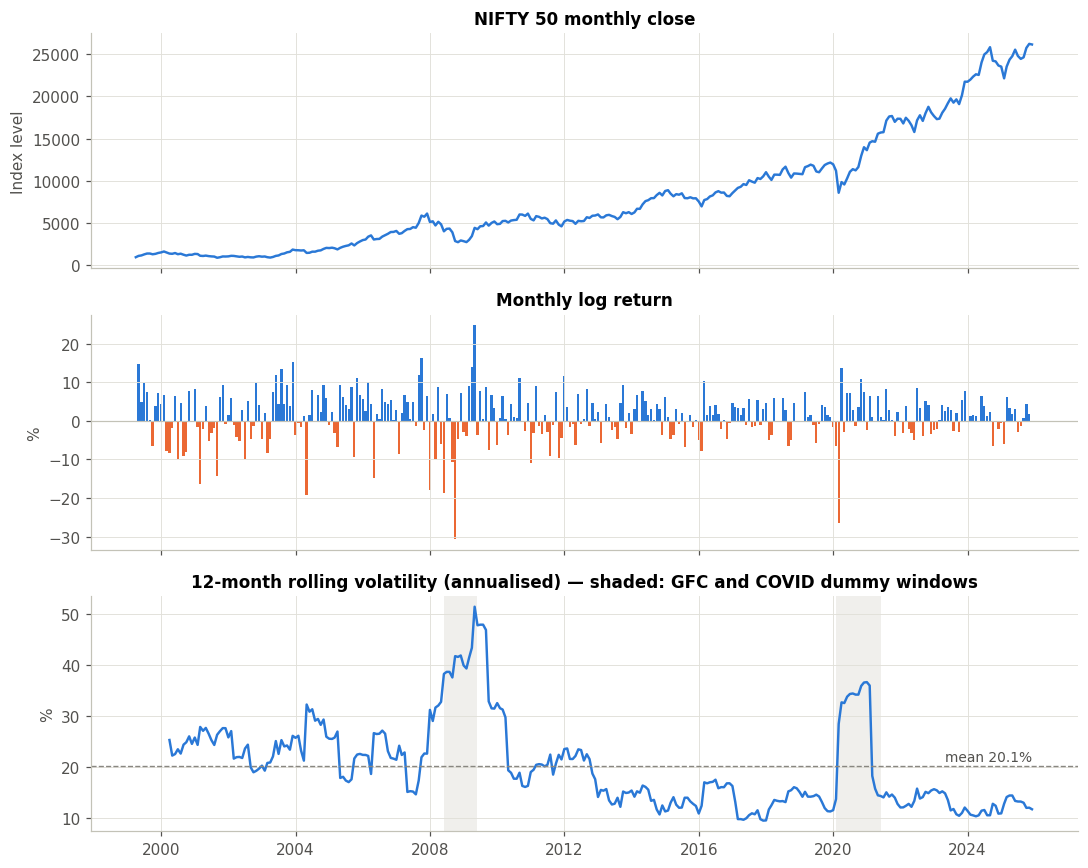

In [12]:
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax[0].plot(df.index, df["Price"], color=C["blue"]); ax[0].set_title("NIFTY 50 monthly close"); ax[0].set_ylabel("Index level")
ax[1].bar(df.index, df["Return"], width=25, color=np.where(df["Return"] >= 0, C["blue"], C["orange"]))
ax[1].axhline(0, color=C["axis"], lw=0.8); ax[1].set_title("Monthly log return"); ax[1].set_ylabel("%")
ax[2].plot(EST.index, EST["RollVol"] * 100, color=C["blue"]); shade_dummies(ax[2])
ax[2].axhline(EST["RollVol"].mean() * 100, color=C["muted"], lw=0.9, ls="--")
ax[2].text(EST.index[-1], EST["RollVol"].mean() * 100 + 1.0, f"mean {EST['RollVol'].mean()*100:.1f}%", color=C["ink2"], fontsize=9, ha="right")
ax[2].set_title("12-month rolling volatility (annualised) — shaded: GFC and COVID dummy windows"); ax[2].set_ylabel("%")
year_axis(ax[2]); fig.tight_layout(); save_fig(fig, "F01_nse_price_returns_rollvol")

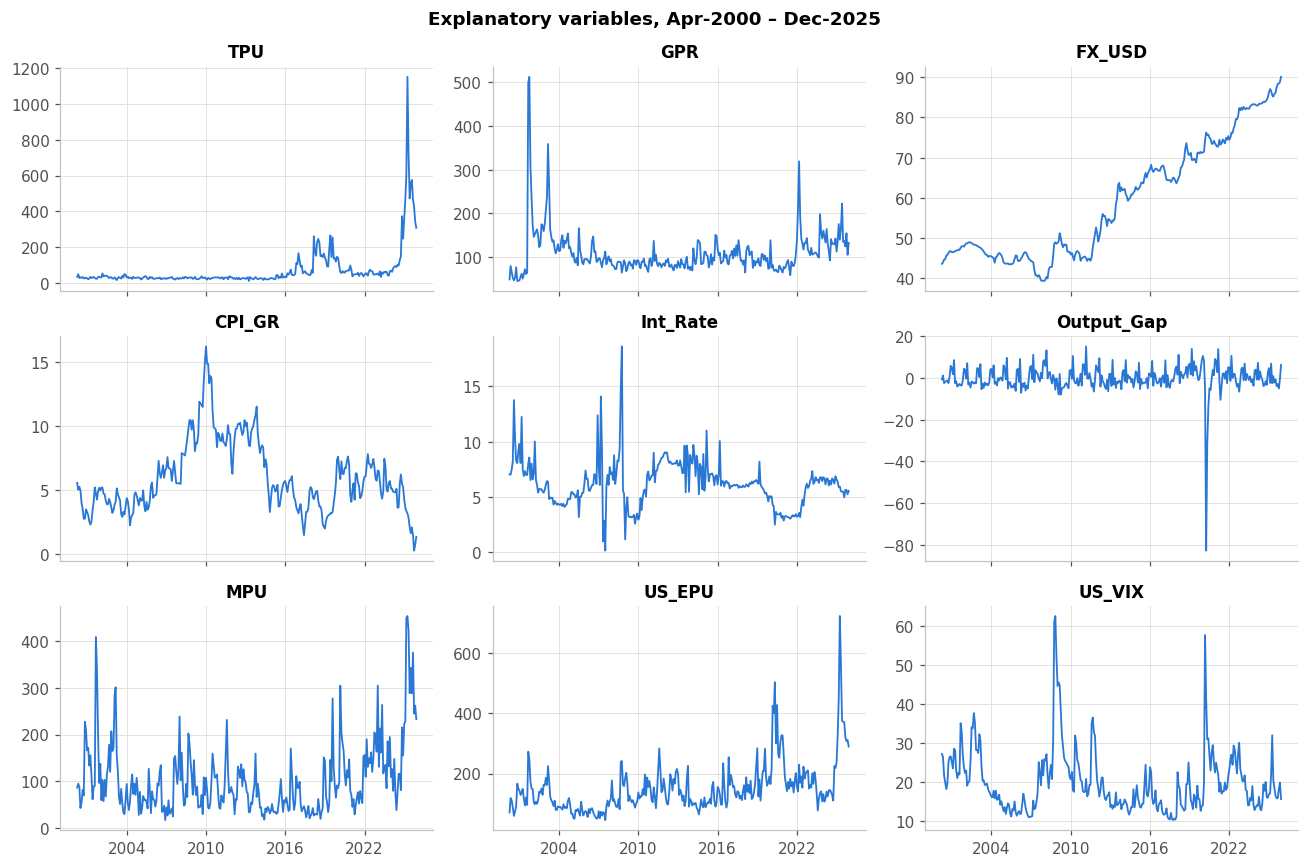

In [13]:
plot_vars = ["TPU", "GPR"] + CONTROLS
fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True)
for a, v in zip(axes.flat, plot_vars):
    a.plot(EST.index, EST[v], color=C["blue"], lw=1.2); a.set_title(v); year_axis(a, 6)
fig.suptitle("Explanatory variables, Apr-2000 – Dec-2025", fontweight="bold"); fig.tight_layout()
save_fig(fig, "F02_explanatory_variables")

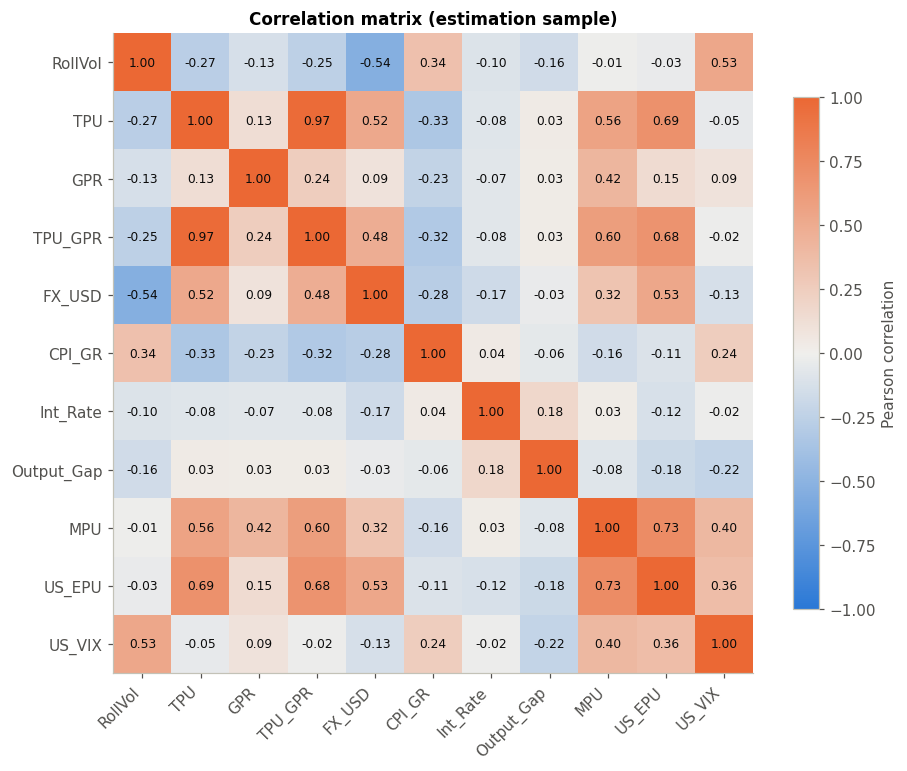

In [14]:
corr_vars = ["RollVol", "TPU", "GPR", "TPU_GPR"] + CONTROLS
corr = EST[corr_vars].corr()
save_table(corr.round(3), "T04_correlation_matrix", show=False)
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_vars))); ax.set_xticklabels(corr_vars, rotation=45, ha="right")
ax.set_yticks(range(len(corr_vars))); ax.set_yticklabels(corr_vars); ax.grid(False)
for i in range(len(corr_vars)):
    for j in range(len(corr_vars)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8, color=C["ink"])
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation matrix (estimation sample)"); fig.tight_layout(); save_fig(fig, "F03_correlation_heatmap")

## 4. Stage 1 — GARCH(1,1) and GARCH-X(1,1) on monthly NIFTY returns
GARCH-X specification (as in the report, eqs. 1–2), estimated jointly by Gaussian maximum likelihood:

$$r_t=\mu+\beta_1 TPU_t+\beta_2 GPR_t+\varepsilon_t,\qquad
  \sigma^2_t=\omega+\alpha\varepsilon^2_{t-1}+\beta\sigma^2_{t-1}+\delta_1 TPU_t+\delta_2 GPR_t$$

$\sigma^2_0$ is set to the sample variance of returns; standard errors come from the inverse numerical Hessian.
A plain GARCH(1,1) ($\beta_1=\beta_2=\delta_1=\delta_2=0$) is estimated the same way for a likelihood-ratio test.



In [15]:
G = df.dropna(subset=["Return"])
r_g, tpu_g, gpr_g = G["Return"].values, G["TPU"].values, G["GPR"].values
T_g = len(r_g)

def garch_path(p, with_x):
    if with_x: mu, b1, b2, om, al, be, d1, d2 = p
    else:      mu, om, al, be = p; b1 = b2 = d1 = d2 = 0.0
    e = r_g - mu - b1 * tpu_g - b2 * gpr_g
    s2 = np.empty(T_g); s2[0] = np.var(r_g)
    for t in range(1, T_g):
        s2[t] = om + al * e[t-1]**2 + be * s2[t-1] + d1 * tpu_g[t] + d2 * gpr_g[t]
        if s2[t] <= 0: return e, None
    return e, s2

def garch_nll(p, with_x):
    om, al, be = (p[3], p[4], p[5]) if with_x else (p[1], p[2], p[3])
    if om <= 0 or al < 0 or be < 0 or al + be >= 1: return 1e10
    e, s2 = garch_path(p, with_x)
    if s2 is None: return 1e10
    return 0.5 * np.sum(np.log(2 * np.pi * s2) + e**2 / s2)

def num_hessian(f, x, eps=1e-5):
    n = len(x); H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            ei = np.zeros(n); ej = np.zeros(n); ei[i] = eps; ej[j] = eps
            H[i, j] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * eps**2)
    return H

def fit_garch(with_x, init):
    bnds = ([(None, None)] * 3 + [(1e-6, None), (1e-6, .999), (1e-6, .999), (None, None), (None, None)]) if with_x \
           else [(None, None), (1e-6, None), (1e-6, .999), (1e-6, .999)]
    f = lambda p: garch_nll(p, with_x)
    res = minimize(f, init, method="L-BFGS-B", bounds=bnds, options={"maxiter": 5000, "ftol": 1e-14, "gtol": 1e-8})
    se = np.sqrt(np.abs(np.diag(np.linalg.inv(num_hessian(f, res.x)))))
    return res, se

init_x = [r_g.mean(), 0.01, 0.01, np.var(r_g) * 0.1, 0.10, 0.80, 0.01, 0.01]      # same start as original code
init_0 = [r_g.mean(), np.var(r_g) * 0.1, 0.10, 0.80]
res_x, se_x = fit_garch(True, init_x)
res_0, se_0 = fit_garch(False, init_0)
print("GARCH-X converged:", res_x.success, "| GARCH(1,1) converged:", res_0.success)

# multi-start robustness (report §8 claims convergence from several starting values)
rng = np.random.default_rng(SEED); ll_starts = []
while len(ll_starts) < 10:
    st = np.array(init_x) * rng.uniform(0.5, 1.5, 8); st[4], st[5] = rng.uniform(.03, .2), rng.uniform(.6, .9)
    st[6], st[7] = rng.uniform(-0.002, 0.01), rng.uniform(-0.002, 0.01)
    if garch_nll(st, True) >= 1e9: continue                     # skip infeasible starting points
    rk = minimize(lambda p: garch_nll(p, True), st, method="L-BFGS-B",
                  bounds=[(None, None)] * 3 + [(1e-6, None), (1e-6, .999), (1e-6, .999), (None, None), (None, None)],
                  options={"maxiter": 5000, "ftol": 1e-14, "gtol": 1e-8})
    ll_starts.append(-rk.fun)
n_same = sum(abs(l - (-res_x.fun)) < 0.01 for l in ll_starts)
print(f"Multi-start (10 feasible random starts): {n_same}/10 reach the baseline optimum LL={-res_x.fun:.4f}; "
      f"best {max(ll_starts):.4f}, worst {min(ll_starts):.4f}")

GARCH-X converged: True | GARCH(1,1) converged: True
Multi-start (10 feasible random starts): 10/10 reach the baseline optimum LL=-1022.6835; best -1022.6835, worst -1022.6835


In [16]:
names_x = ["μ (mean)", "β1 TPU → mean", "β2 GPR → mean", "ω", "α (ARCH)", "β (GARCH)", "δ1 TPU → variance", "δ2 GPR → variance"]
z_x = res_x.x / se_x; p_x = 2 * (1 - stats.norm.cdf(np.abs(z_x)))
tab_gx = pd.DataFrame({"Equation": ["Mean"] * 3 + ["Variance"] * 5, "Parameter": names_x, "Coef": res_x.x,
                       "SE": se_x, "z": z_x, "p-value": p_x, "Sig": [stars(p) for p in p_x]})
names_0 = ["μ (mean)", "ω", "α (ARCH)", "β (GARCH)"]
z_0 = res_0.x / se_0; p_0 = 2 * (1 - stats.norm.cdf(np.abs(z_0)))
tab_g0 = pd.DataFrame({"Parameter": names_0, "Coef": res_0.x, "SE": se_0, "z": z_0, "p-value": p_0, "Sig": [stars(p) for p in p_0]})

e_x, s2_x = garch_path(res_x.x, True); e_0, s2_0 = garch_path(res_0.x, False)
z_std = e_x / np.sqrt(s2_x)
lb1 = acorr_ljungbox(z_std, lags=[5, 10], return_df=True); lb2 = acorr_ljungbox(z_std**2, lags=[5, 10], return_df=True)
LR = 2 * (res_0.fun - res_x.fun); LR_p = 1 - stats.chi2.cdf(LR, 4)
ll_x, ll_0 = -res_x.fun, -res_0.fun
fit_g = pd.DataFrame({
    "Statistic": ["N", "Log-likelihood", "AIC", "BIC", "α+β (persistence)", "Ljung-Box z (lag 5 / 10) p",
                  "Ljung-Box z² (lag 5 / 10) p", "LR test GARCH-X vs GARCH(1,1): χ²(4)", "LR p-value",
                  "Multi-start LL range"],
    "GARCH-X(1,1)": [T_g, ll_x, 2 * 8 - 2 * ll_x, 8 * np.log(T_g) - 2 * ll_x, res_x.x[4] + res_x.x[5],
                     f"{lb1.lb_pvalue.iloc[0]:.3f} / {lb1.lb_pvalue.iloc[1]:.3f}",
                     f"{lb2.lb_pvalue.iloc[0]:.3f} / {lb2.lb_pvalue.iloc[1]:.3f}", LR, LR_p,
                     f"{n_same}/10 starts reach optimum; range {min(ll_starts):.2f} – {max(ll_starts):.2f}"],
    "GARCH(1,1)": [T_g, ll_0, 2 * 4 - 2 * ll_0, 4 * np.log(T_g) - 2 * ll_0, res_0.x[2] + res_0.x[3], "", "", "", "", ""]})
save_table(tab_gx.round(6), "T05_garchx_coefficients", index=False)
save_table(tab_g0.round(6), "T06_garch11_coefficients", index=False)
save_table(fit_g, "T07_garch_fit_statistics", index=False)
KEY["garchx"] = {n: [round(c, 4), round(p, 3)] for n, c, p in zip(names_x, res_x.x, p_x)}
KEY["garchx_persistence"] = round(res_x.x[4] + res_x.x[5], 3); KEY["garchx_LR_p"] = round(LR_p, 3)

df["GARCHX_Vol"] = pd.Series(np.sqrt(s2_x), index=G.index)

,Equation,Parameter,Coef,SE,z,p-value,Sig
0,Mean,μ (mean),1.276765,0.735001,1.737094,0.082371,*
1,Mean,β1 TPU → mean,0.000037,0.001604,0.023139,0.981540,
2,Mean,β2 GPR → mean,-0.002420,0.006023,-0.401742,0.687874,
3,Variance,ω,4.259747,2.044908,2.083100,0.037242,**
4,Variance,α (ARCH),0.135612,0.054819,2.473829,0.013367,**
5,Variance,β (GARCH),0.800932,0.065627,12.204374,0.000000,***
6,Variance,δ1 TPU → variance,-0.005264,0.003157,-1.667212,0.095472,*
7,Variance,δ2 GPR → variance,-0.011455,0.014141,-0.810055,0.417909,


,Parameter,Coef,SE,z,p-value,Sig
0,μ (mean),0.991337,0.296883,3.339147,0.000840,***
1,ω,1.864946,1.040541,1.792286,0.073087,*
2,α (ARCH),0.128524,0.055798,2.303363,0.021258,**
3,β (GARCH),0.828158,0.062306,13.291788,0.000000,***


,Statistic,"GARCH-X(1,1)","GARCH(1,1)"
0,N,320,320
1,Log-likelihood,-1022.683525,-1024.44208
2,AIC,2061.367049,2056.884159
3,BIC,2091.513617,2071.957443
4,α+β (persistence),0.936544,0.956683
5,Ljung-Box z (lag 5 / 10) p,0.521 / 0.649,
6,Ljung-Box z² (lag 5 / 10) p,0.859 / 0.911,
7,"LR test GARCH-X vs GARCH(1,1): χ²(4)",3.51711,
8,LR p-value,0.475282,
9,Multi-start LL range,10/10 starts reach optimum; range -1022.68 – -...,


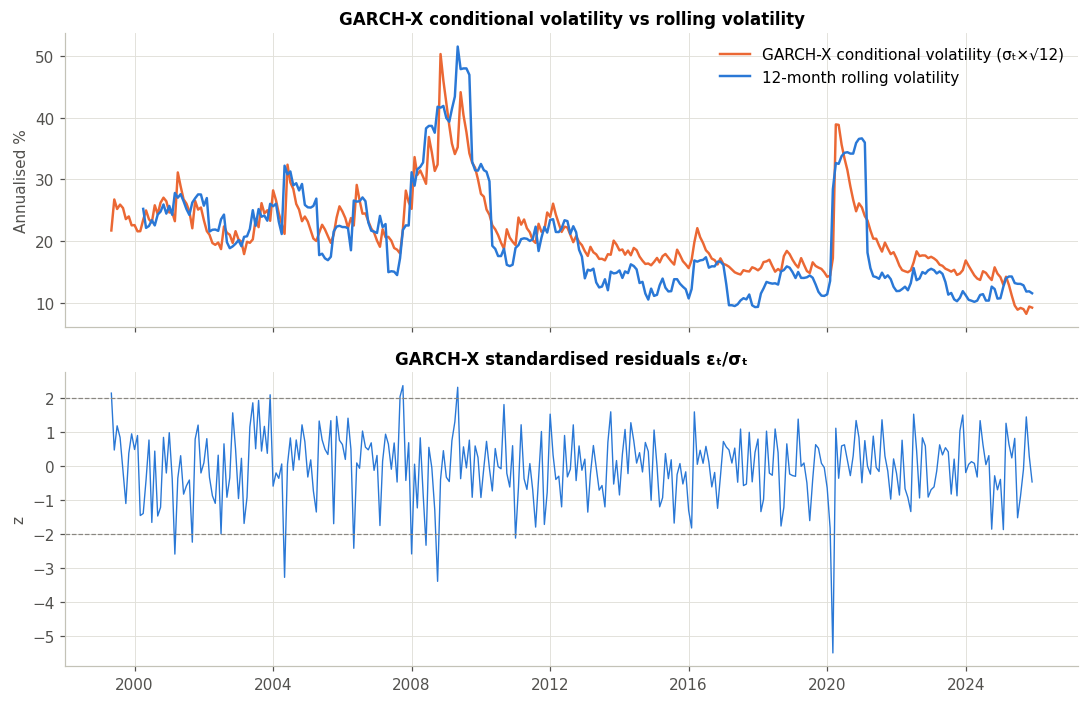

Correlation GARCH-X σ vs RollVol: 0.895


In [17]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
ax[0].plot(G.index, df.loc[G.index, "GARCHX_Vol"] * np.sqrt(12), color=C["orange"], label="GARCH-X conditional volatility (σₜ×√12)")
ax[0].plot(EST.index, EST["RollVol"] * 100, color=C["blue"], label="12-month rolling volatility")
ax[0].set_ylabel("Annualised %"); ax[0].legend(loc="upper right"); ax[0].set_title("GARCH-X conditional volatility vs rolling volatility")
ax[1].plot(G.index, z_std, color=C["blue"], lw=0.9); ax[1].axhline(2, color=C["muted"], ls="--", lw=0.8)
ax[1].axhline(-2, color=C["muted"], ls="--", lw=0.8); ax[1].set_title("GARCH-X standardised residuals εₜ/σₜ"); ax[1].set_ylabel("z")
year_axis(ax[1]); fig.tight_layout(); save_fig(fig, "F04_garchx_volatility_and_residuals")
print("Correlation GARCH-X σ vs RollVol:", round(df["GARCHX_Vol"].corr(df["RollVol"]), 3))

In [18]:
master = df[["Price", "Return", "RollVol", "GARCHX_Vol", "TPU", "GPR", "TPU_GPR"] + CONTROLS].copy()
notes = pd.DataFrame({"Column": master.columns, "Definition": [
    "NIFTY 50 monthly close (NSE_monthly_final.csv)", "100·ln(Pt/Pt−1)",
    "sd(monthly log returns, 12-month window)·√12, decimal — DEPENDENT VARIABLE of Stages 2–3",
    "GARCH-X(1,1) conditional volatility, monthly % (Stage 1 only)", "Trade Policy Uncertainty (India)",
    "Geopolitical Risk index", "TPU×GPR", "INR/USD", "CPI inflation, % y/y",
    "Weighted avg. call money rate, % (Mar-2007 corrected to 14.07)" if FIX_INT_RATE_MAR2007 else "Weighted avg. call money rate, %",
    "Output gap, % (HP filter)", "Monetary Policy Uncertainty", "US Economic Policy Uncertainty", "CBOE VIX (monthly mean)"]})
with pd.ExcelWriter(OUT_DIR / "master_dataset.xlsx") as w:
    master.reset_index().to_excel(w, sheet_name="data", index=False); notes.to_excel(w, sheet_name="definitions", index=False)
EST = df.loc[df["RollVol"].notna()].copy()
print("Saved outputs/master_dataset.xlsx", master.shape)

Saved outputs/master_dataset.xlsx (321, 14)


## 5. Stationarity tests
ADF (constant, lag length by AIC, max 12) and Phillips–Perron (constant) — H0: unit root; KPSS (level) — H0: stationary.
All tests use the **same estimation sample (Apr-2000 → Dec-2025)**, in levels and first differences.

Classification: **I(0)** if ADF and PP both reject at 5 %; **I(1)** if neither rejects in levels and both reject in
differences; otherwise **Mixed** (KPSS reported as tie-breaker). The Zivot–Andrews test allows one structural break.

In [19]:
def unit_root_row(s):
    s = s.dropna()
    adf = adfuller(s, maxlag=12, regression="c", autolag="AIC")
    pp = PhillipsPerron(s, trend="c")
    kp = kpss(s, regression="c", nlags="auto")
    return adf[0], adf[1], pp.stat, pp.pvalue, kp[0], kp[1]

ur_vars = ["RollVol", "lnRollVol", "TPU", "GPR", "TPU_GPR"] + CONTROLS
EST["lnRollVol"] = np.log(EST["RollVol"])
rows = []
for v in ur_vars:
    L = unit_root_row(EST[v]); D = unit_root_row(EST[v].diff())
    lvl0 = L[1] < .05 and L[3] < .05
    dif0 = D[1] < .05 and D[3] < .05
    if lvl0: cls = "I(0)"
    elif L[1] >= .05 and L[3] >= .05 and dif0: cls = "I(1)"
    else: cls = "Mixed → " + ("I(0)" if L[5] >= .05 else "I(1)") + " by KPSS"
    rows.append({"Variable": v, "ADF stat": L[0], "ADF p": L[1], "PP stat": L[2], "PP p": L[3], "KPSS stat": L[4],
                 "KPSS p": L[5], "ΔADF p": D[1], "ΔPP p": D[3], "ΔKPSS p": D[5], "Classification": cls})
ur = pd.DataFrame(rows).set_index("Variable")
save_table(ur.round(4), "T08_unit_root_tests")
KEY["unit_root"] = {v: [round(ur.loc[v, "ADF p"], 3), round(ur.loc[v, "PP p"], 3), ur.loc[v, "Classification"]] for v in ur.index}

,ADF stat,ADF p,PP stat,PP p,KPSS stat,KPSS p,ΔADF p,ΔPP p,ΔKPSS p,Classification
Variable,,,,,,,,,,
RollVol,-2.1719,0.2166,-2.8006,0.0582,1.0735,0.0100,0.0,0.0,0.1,I(1)
lnRollVol,-1.8059,0.3775,-2.5635,0.1007,1.4294,0.0100,0.0,0.0,0.1,I(1)
TPU,0.3781,0.9807,-3.9025,0.0020,0.9249,0.0100,0.0,0.0,0.1,Mixed → I(1) by KPSS
GPR,-6.0310,0.0000,-6.9232,0.0000,0.2793,0.1000,0.0,0.0,0.1,I(0)
TPU_GPR,0.8386,0.9922,-3.2198,0.0189,0.7779,0.0100,0.0,0.0,0.1,Mixed → I(1) by KPSS
FX_USD,0.6403,0.9886,0.8846,0.9954,2.4655,0.0100,0.0,0.0,0.1,I(1)
CPI_GR,-1.3281,0.6162,-2.0468,0.2673,0.4221,0.0676,0.0,0.0,0.1,I(1)
Int_Rate,-4.1790,0.0007,-9.3143,0.0000,0.2970,0.1000,0.0,0.0,0.1,I(0)
Output_Gap,-5.2421,0.0000,-11.7988,0.0000,0.0180,0.1000,0.0,0.0,0.1,I(0)


In [20]:
za_rows = []
for v in ["RollVol", "TPU", "GPR", "FX_USD", "CPI_GR", "Int_Rate", "MPU", "US_EPU"]:
    za = zivot_andrews(EST[v].values, trim=0.15, maxlag=12, regression="c", autolag="AIC")
    za_rows.append({"Variable": v, "ZA stat": za[0], "p-value": za[1], "Break date": EST.index[za[4]].strftime("%b-%Y")})
save_table(pd.DataFrame(za_rows).set_index("Variable").round(4), "T09_zivot_andrews_break_tests")

,ZA stat,p-value,Break date
Variable,,,
RollVol,-3.5167,0.6688,Apr-2011
TPU,-4.2954,0.1940,Feb-2022
GPR,-7.0414,0.0000,Sep-2004
FX_USD,-3.2794,0.8052,Aug-2004
CPI_GR,-2.8583,0.9445,Nov-2013
Int_Rate,-4.8019,0.0516,Apr-2010
MPU,-5.7516,0.0015,Nov-2021
US_EPU,-4.8564,0.0449,Apr-2019


,ZA stat,p-value,Break date
Variable,,,
RollVol,-3.5167,0.6688,Apr-2011
TPU,-4.2954,0.1940,Feb-2022
GPR,-7.0414,0.0000,Sep-2004
FX_USD,-3.2794,0.8052,Aug-2004
CPI_GR,-2.8583,0.9445,Nov-2013
Int_Rate,-4.8019,0.0516,Apr-2010
MPU,-5.7516,0.0015,Nov-2021
US_EPU,-4.8564,0.0449,Apr-2019


## 6. Johansen cointegration
Trace tests on (i) the full 10-variable system {RollVol, TPU, GPR, 7 controls} with one lagged difference and
(ii) the 3-variable system {TPU, GPR, RollVol} with two lagged differences (the original specifications).

**Interpretation caveat.** Johansen's rank counts *stationary linear combinations*. Every I(0) variable in the system
is trivially one such combination, so with several I(0) variables (GPR, Int_Rate, Output_Gap, MPU, US_EPU, US_VIX)
a high or full rank says little about genuine long-run relationships. A full rank (r = n) means the system is
stationary in levels.

In [21]:
# Johansen lag = (lag order of the levels VAR) − 1, with the VAR lag chosen by an information criterion.
# The test is only informative for the system whose specification it decides: {TPU, GPR, RollVol},
# which feeds the SVAR and the TVP regression.

def johansen_lag(data, maxlags=12, ic="bic"):
    """Return k_ar_diff = p − 1, where p is the levels-VAR lag chosen by `ic`."""
    sel = VAR(data).select_order(maxlags=maxlags)
    p = max(int(getattr(sel, ic)), 1)
    return p - 1, {"AIC": sel.aic, "BIC": sel.bic, "HQIC": sel.hqic}

def johansen_table(data, k_ar_diff, label):
    j = coint_johansen(data, det_order=0, k_ar_diff=k_ar_diff)
    t = pd.DataFrame({"H0: r ≤": range(len(j.lr1)), "Trace": j.lr1, "CV 90%": j.cvt[:, 0], "CV 95%": j.cvt[:, 1],
                      "CV 99%": j.cvt[:, 2], "Max-eigen": j.lr2, "ME CV 95%": j.cvm[:, 1]})
    t["Reject 5% (trace)"] = t["Trace"] > t["CV 95%"]
    rank = int(np.argmin(t["Reject 5% (trace)"].values)) if not t["Reject 5% (trace)"].all() else len(t)
    print(f"{label}: VAR({k_ar_diff + 1}) in levels → k_ar_diff = {k_ar_diff}; "
          f"trace-test rank at 5% = {rank} of {data.shape[1]} (N={len(data)})")
    return t, rank

# (1) Decision-relevant test: the SVAR / TVP system
SV3 = ["TPU", "GPR", "RollVol"]
k3, ic3 = johansen_lag(EST[SV3])
print("3-variable VAR lag selection (levels):", ic3)
jt_3, rank_3 = johansen_table(EST[SV3], k3, "3-variable system")
save_table(jt_3.round(3), "T11_johansen_3var_system", index=False)

# Robustness: the rank should not hinge on the lag choice
rob_3 = pd.DataFrame([{"k_ar_diff": k, "VAR lag (levels)": k + 1,
                       "Trace r≤0": coint_johansen(EST[SV3], 0, k).lr1[0],
                       "Rank (5%)": johansen_table(EST[SV3], k, f"  robustness k={k}")[1]} for k in range(3)])
save_table(rob_3.round(3), "T11b_johansen_3var_lag_robustness", index=False)

if rank_3 == len(SV3):
    joh_decision = "Full rank: the system is stationary in levels → SVAR and TVP regression in levels."
elif rank_3 > 0:
    joh_decision = f"{rank_3} cointegrating vector(s): a levels VAR is consistent (or estimate a VECM)."
else:
    joh_decision = "No cointegration among I(1) series → estimate the VAR in first differences."
print("Decision:", joh_decision)

# (2) Descriptive only: the full 10-variable system.
#     Johansen assumes I(1) inputs; six of these ten variables are I(0) and each adds a trivially
#     stationary combination, so this rank is NOT used to choose any model.
full_vars = ["RollVol", "TPU", "GPR"] + CONTROLS
k_full, ic_full = johansen_lag(EST[full_vars])
print("Full-system VAR lag selection (levels):", ic_full)
jt_full, rank_full = johansen_table(EST[full_vars], k_full, "Full 10-variable system (descriptive)")
save_table(jt_full.round(3), "T10_johansen_full_system", index=False)

KEY["johansen"] = {"three_k_ar_diff": k3, "three_rank": rank_3, "three_trace": [round(x, 2) for x in jt_3.Trace],
                   "three_rank_by_lag": rob_3["Rank (5%)"].tolist(), "decision": joh_decision,
                   "full_k_ar_diff": k_full, "full_rank": rank_full, "full_trace_r0": round(jt_full.Trace[0], 2)}

3-variable VAR lag selection (levels): {'AIC': np.int64(1), 'BIC': np.int64(1), 'HQIC': np.int64(1)}
3-variable system: VAR(1) in levels → k_ar_diff = 0; trace-test rank at 5% = 3 of 3 (N=309)


,H0: r ≤,Trace,CV 90%,CV 95%,CV 99%,Max-eigen,ME CV 95%,Reject 5% (trace)
0,0,74.069,27.067,29.796,35.463,46.431,21.131,True
1,1,27.637,13.429,15.494,19.935,20.415,14.264,True
2,2,7.222,2.706,3.842,6.635,7.222,3.842,True


  robustness k=0: VAR(1) in levels → k_ar_diff = 0; trace-test rank at 5% = 3 of 3 (N=309)
  robustness k=1: VAR(2) in levels → k_ar_diff = 1; trace-test rank at 5% = 3 of 3 (N=309)
  robustness k=2: VAR(3) in levels → k_ar_diff = 2; trace-test rank at 5% = 3 of 3 (N=309)


,k_ar_diff,VAR lag (levels),Trace r≤0,Rank (5%)
0,0,1,74.069,3
1,1,2,72.847,3
2,2,3,53.702,3


Decision: Full rank: the system is stationary in levels → SVAR and TVP regression in levels.
Full-system VAR lag selection (levels): {'AIC': np.int64(2), 'BIC': np.int64(1), 'HQIC': np.int64(1)}
Full 10-variable system (descriptive): VAR(1) in levels → k_ar_diff = 0; trace-test rank at 5% = 8 of 10 (N=309)


,H0: r ≤,Trace,CV 90%,CV 95%,CV 99%,Max-eigen,ME CV 95%,Reject 5% (trace)
0,0,614.349,232.103,239.247,253.253,184.234,64.504,True
1,1,430.115,190.871,197.377,210.037,110.933,58.433,True
2,2,319.183,153.634,159.529,171.090,85.586,52.362,True
3,3,233.597,120.367,125.618,135.982,75.231,46.230,True
4,4,158.366,91.109,95.754,104.964,55.022,40.076,True
5,5,103.345,65.820,69.819,77.820,45.520,33.878,True
6,6,57.824,44.493,47.854,54.682,25.744,27.586,True
7,7,32.080,27.067,29.796,35.463,17.689,21.131,True
8,8,14.391,13.429,15.494,19.935,9.232,14.264,False
9,9,5.159,2.706,3.842,6.635,5.159,3.842,True


## 7. ARDL models
Both specifications use `RollVol` (or its log) as the dependent variable and two period dummies
(D_GFC Jun-2008 – Jun-2009, D_COVID Feb-2020 – Jun-2021), each kept only if significant at 10 % in a static
screening regression (the original procedure).

**Bounds test.** The original code computed a Wald test on the *contemporaneous* regressors of the levels ARDL. That is
not the Pesaran–Shin–Smith (2001) test, and its critical-value table was also mis-typed for k ≥ 2. Here the test is done
properly: the ARDL is re-written exactly as an unrestricted error-correction model
$\Delta y_t=c+\pi_y y_{t-1}+\sum_j\pi_j x_{j,t-1}+\text{short-run }\Delta\text{ terms}+\text{dummies}$ (for a regressor with
zero lags its level enters at *t*), and $H_0:\pi_y=\pi_1=\dots=\pi_k=0$ is tested with an F statistic against the
PSS Case III bounds (unrestricted intercept, no trend). Critical values and p-values come from `statsmodels`' PSS tables.

**Long-run multipliers** $\theta_j=\sum_l\beta_{j,l}/(1-\sum_i\phi_i)$ are reported with delta-method standard errors.

In [22]:
from statsmodels.tsa.ardl import pss_critical_values as PSS
from statsmodels.tsa.ardl.model import _pss_pvalue

def make_dummies(index):
    return pd.DataFrame({n: ((index >= a) & (index <= b)).astype(int) for n, (a, b) in D_PERIODS.items()}, index=index)

def screen_dummies(data, y, regs, alpha=0.10):
    d = data[regs + [y]].dropna(); dm = make_dummies(d.index); out = []
    for c in dm.columns:
        r = sm.OLS(d[y], sm.add_constant(pd.concat([d[regs], dm[[c]]], axis=1))).fit()
        out.append({"Dummy": c, "Coef": r.params[c], "p-value": r.pvalues[c], "Kept": r.pvalues[c] < alpha})
    return pd.DataFrame(out)

def ardl_frame(data, y, regs, p, q, dummies, panel):
    """Levels ARDL(p,q) design. Lags are taken from the full panel so no observation is lost unnecessarily."""
    out = pd.DataFrame(index=data.index); out[y] = data[y]
    for l in range(1, p + 1): out[f"{y}_L{l}"] = panel[y].shift(l).reindex(data.index)
    for v in regs:
        out[v] = data[v]
        for l in range(1, q + 1): out[f"{v}_L{l}"] = panel[v].shift(l).reindex(data.index)
    for dname in dummies: out[dname] = make_dummies(data.index)[dname]
    return out.dropna()

def bounds_test(design, y, regs, p, q, dummies):
    """Exact UECM re-parametrisation of the ARDL design + PSS Case III F-test."""
    u = pd.DataFrame(index=design.index)
    ylag = lambda l: design[y] if l == 0 else design[f"{y}_L{l}"]
    xlag = lambda v, l: design[v] if l == 0 else design[f"{v}_L{l}"]
    u["dy"] = ylag(0) - ylag(1)
    u["y_L1(level)"] = ylag(1)
    for v in regs: u[f"{v}(level)"] = xlag(v, 1) if q >= 1 else xlag(v, 0)
    for i in range(1, p): u[f"dy_L{i}"] = ylag(i) - ylag(i + 1)
    for v in regs:
        for l in range(0, q): u[f"d{v}_L{l}"] = xlag(v, l) - xlag(v, l + 1)
    for dname in dummies: u[dname] = design[dname]
    X = sm.add_constant(u.drop(columns="dy")); r = sm.OLS(u["dy"], X).fit()
    lev = ["y_L1(level)"] + [f"{v}(level)" for v in regs]
    R = np.zeros((len(lev), X.shape[1]))
    for i, c in enumerate(lev): R[i, list(X.columns).index(c)] = 1
    F = float(np.squeeze(r.f_test(R).fvalue)); k = len(regs)
    i5 = list(PSS.crit_percentiles).index(95); i10 = list(PSS.crit_percentiles).index(90); i1 = list(PSS.crit_percentiles).index(99)
    cv = {lvl: (PSS.crit_vals[(k, 3, False)][i], PSS.crit_vals[(k, 3, True)][i]) for lvl, i in [("10%", i10), ("5%", i5), ("1%", i1)]}
    p_lo, p_up = _pss_pvalue(F, k, 3, False), _pss_pvalue(F, k, 3, True)
    t_y = float(r.tvalues["y_L1(level)"])
    Rx = R[1:]; F_x = float(np.squeeze(r.f_test(Rx).fvalue))
    concl = ("Reject H0 → long-run level relationship" if F > cv["5%"][1] else
             "Do not reject H0 → no long-run relationship" if F < cv["5%"][0] else "Inconclusive (between bounds)")
    return {"F": F, "k": k, "cv": cv, "p_I0": p_lo, "p_I1": p_up, "conclusion": concl, "uecm": r,
            "t_y": t_y, "F_x": F_x}

def lr_multipliers(res, y, regs, p, q):
    b = res.params; V = res.cov_params(); phi = [f"{y}_L{l}" for l in range(1, p + 1)]
    D = 1 - b[phi].sum(); out = []
    for v in regs:
        terms = [v] + [f"{v}_L{l}" for l in range(1, q + 1)]
        num = b[terms].sum(); theta = num / D
        g = pd.Series(0.0, index=b.index); g[terms] = 1 / D; g[phi] = num / D**2
        se = float(np.sqrt(g @ V @ g)); zst = theta / se; pv = 2 * (1 - stats.norm.cdf(abs(zst)))
        out.append({"Variable": v, "SR (contemp.)": b[v], "SR p-value": res.pvalues[v], "LR multiplier": theta,
                    "LR SE (delta)": se, "LR p-value": pv, "LR Sig": stars(pv)})
    return pd.DataFrame(out).set_index("Variable"), D

def ardl_diagnostics(res, design, y, p, extra=True):
    resid = res.resid; lb = acorr_ljungbox(resid, lags=[12], return_df=True)
    bp = het_breuschpagan(resid, res.model.exog); jb = jarque_bera(resid)
    persistence = 1 - (1 - res.params[[f"{y}_L{l}" for l in range(1, p + 1)]].sum())
    d = {"N": int(res.nobs), "R²": res.rsquared, "Adj. R²": res.rsquared_adj, "AIC": res.aic, "BIC": res.bic,
         "Durbin–Watson": durbin_watson(resid), "Ljung–Box Q(12) p": lb.lb_pvalue.iloc[0], "Breusch–Pagan p": bp[1],
         "Jarque–Bera p": jb[1], "Σφ (persistence)": persistence,
         "Speed of adjustment 1−Σφ": 1 - persistence, "Half-life of a shock (months)": np.log(0.5) / np.log(persistence)}
    if extra:
        ols = sm.OLS(res.model.endog, res.model.exog).fit()
        d["Ramsey RESET p (power 2)"] = float(linear_reset(ols, power=2, use_f=True).pvalue)
        d["CUSUM (OLS resid) p"] = breaks_cusumolsresid(ols.resid, ddof=ols.df_model + 1)[1]
    return pd.Series(d)

### 7.1 Base ARDL(2,2) — RollVol on TPU, GPR, TPU×GPR and seven controls, HC3 standard errors

In [23]:
Y1 = "RollVol"; REG1 = ["TPU", "GPR", "TPU_GPR"] + CONTROLS; P1, Q1 = 2, 2
scr1 = screen_dummies(EST, Y1, REG1); save_table(scr1.round(4), "T12_ardl_base_dummy_screening", index=False)
DUM1 = scr1.loc[scr1.Kept, "Dummy"].tolist()
des1 = ardl_frame(EST, Y1, REG1, P1, Q1, DUM1, df)
res1 = sm.OLS(des1[Y1], sm.add_constant(des1.drop(columns=Y1))).fit(cov_type="HC3")
print(res1.summary())

,Dummy,Coef,p-value,Kept
0,D_GFC,0.1409,0.0,True
1,D_COVID,0.1098,0.0,True


                            OLS Regression Results                            
Dep. Variable:                RollVol   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.924
Method:                 Least Squares   F-statistic:                     157.0
Date:                Sat, 14 Nov 2026   Prob (F-statistic):          1.42e-158
Time:                        20:53:27   Log-Likelihood:                 734.31
No. Observations:                 307   AIC:                            -1399.
Df Residuals:                     272   BIC:                            -1268.
Df Model:                          34                                         
Covariance Type:                  HC3                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const             0.0560      0.024      2.343

In [24]:
coef1 = pd.DataFrame({"Coef": res1.params, "SE (HC3)": res1.bse, "z": res1.tvalues, "p-value": res1.pvalues})
coef1["Sig"] = coef1["p-value"].map(stars)
save_table(coef1.round(6), "T13_ardl_base_coefficients", show=False)
lr1, D1 = lr_multipliers(res1, Y1, REG1, P1, Q1); save_table(lr1.round(6), "T14_ardl_base_long_run")
bt1 = bounds_test(des1, Y1, REG1, P1, Q1, DUM1)
assert np.allclose(bt1["uecm"].resid.values, sm.OLS(des1[Y1], sm.add_constant(des1.drop(columns=Y1))).fit().resid.values), "UECM ≠ ARDL"
diag1 = ardl_diagnostics(res1, des1, Y1, P1)
diag1["Bounds F (PSS Case III)"] = bt1["F"]; diag1["k"] = bt1["k"]
diag1["5% bounds I(0) / I(1)"] = f"{bt1['cv']['5%'][0]:.2f} / {bt1['cv']['5%'][1]:.2f}"
diag1["10% bounds I(0) / I(1)"] = f"{bt1['cv']['10%'][0]:.2f} / {bt1['cv']['10%'][1]:.2f}"
diag1["p-value vs I(0) / I(1) bound"] = f"{bt1['p_I0']:.3f} / {bt1['p_I1']:.3f}"
diag1["Bounds conclusion (5%)"] = bt1["conclusion"]
diag1["t-stat on y(t−1) in UECM"] = bt1["t_y"]; diag1["F on lagged x-levels only"] = bt1["F_x"]; diag1["Dummies kept"] = ", ".join(DUM1)
save_table(diag1.to_frame("Base ARDL(2,2)"), "T15_ardl_base_diagnostics")
KEY["ardl_base"] = {"N": int(res1.nobs), "R2": round(res1.rsquared, 4), "adjR2": round(res1.rsquared_adj, 4),
                    "Y_L1": [round(res1.params[f"{Y1}_L1"], 4), round(res1.pvalues[f"{Y1}_L1"], 4)],
                    "D_GFC": [round(res1.params.get("D_GFC", np.nan), 4), round(res1.pvalues.get("D_GFC", np.nan), 3)],
                    "D_COVID": [round(res1.params.get("D_COVID", np.nan), 4), round(res1.pvalues.get("D_COVID", np.nan), 3)],
                    "bounds_F": round(bt1["F"], 3), "bounds_5pct": [round(x, 2) for x in bt1["cv"]["5%"]],
                    "bounds_conclusion": bt1["conclusion"], "speed": round(D1, 4), "DW": round(diag1["Durbin–Watson"], 3),
                    "half_life": round(diag1["Half-life of a shock (months)"], 2),
                    "sig_10pct": [c for c in res1.params.index if res1.pvalues[c] < .10]}

,SR (contemp.),SR p-value,LR multiplier,LR SE (delta),LR p-value,LR Sig
Variable,,,,,,
TPU,-0.000010,0.865166,0.000172,0.000497,0.729696,
GPR,-0.000059,0.224970,-0.000047,0.000220,0.830618,
TPU_GPR,-0.000000,0.752050,-0.000002,0.000004,0.602419,
FX_USD,0.000745,0.742625,-0.003764,0.000778,0.000001,***
CPI_GR,0.000563,0.788605,-0.003947,0.004976,0.427682,
Int_Rate,0.000710,0.612675,-0.000619,0.005455,0.909622,
Output_Gap,-0.000327,0.449654,-0.001576,0.003065,0.607078,
MPU,0.000083,0.065986,0.000455,0.000200,0.023156,**
US_EPU,0.000034,0.546507,-0.000035,0.000325,0.913438,


,"Base ARDL(2,2)"
N,307.0
R²,0.932111
Adj. R²,0.923625
AIC,-1398.61099
BIC,-1268.171319
Durbin–Watson,2.012266
Ljung–Box Q(12) p,0.0
Breusch–Pagan p,0.001523
Jarque–Bera p,0.0
Σφ (persistence),0.837925


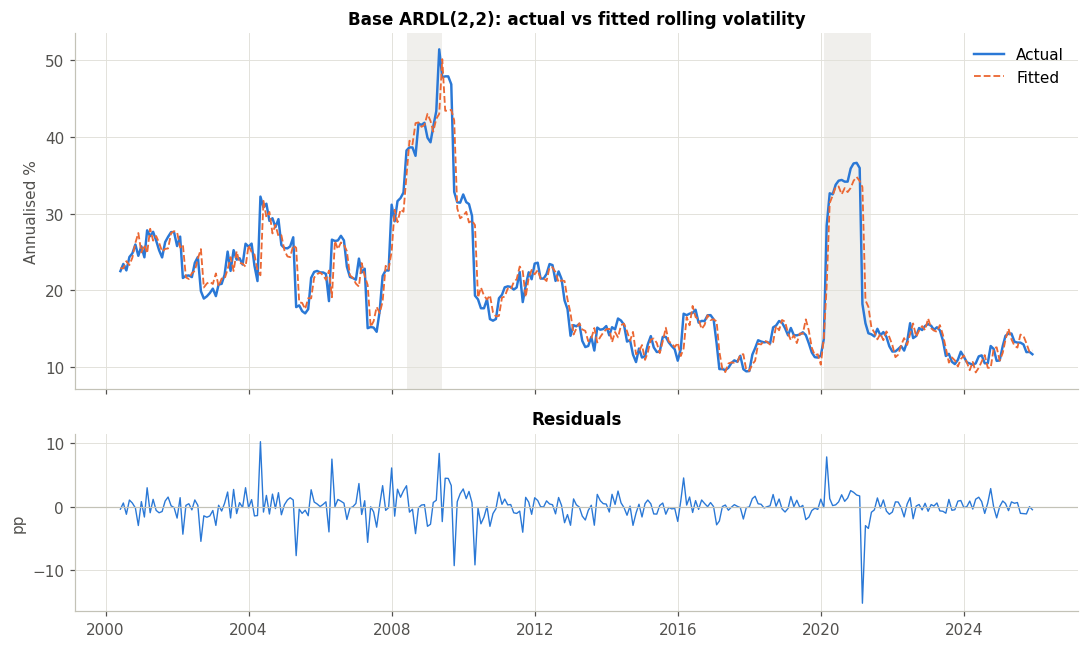

In [25]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
shade_dummies(ax[0]); ax[0].plot(des1.index, des1[Y1] * 100, color=C["blue"], label="Actual")
ax[0].plot(des1.index, res1.fittedvalues * 100, color=C["orange"], lw=1.2, ls="--", label="Fitted")
ax[0].set_ylabel("Annualised %"); ax[0].legend(loc="upper right"); ax[0].set_title("Base ARDL(2,2): actual vs fitted rolling volatility")
ax[1].plot(des1.index, res1.resid * 100, color=C["blue"], lw=0.9); ax[1].axhline(0, color=C["axis"], lw=0.8)
ax[1].set_title("Residuals"); ax[1].set_ylabel("pp"); year_axis(ax[1]); fig.tight_layout(); save_fig(fig, "F05_ardl_base_fit")

### 7.2 Robust ARDL — ln(RollVol), BIC-optimal lags, HAC (Newey–West, 4 lags) standard errors
Same design as the original robust specification: no TPU×GPR, no US_EPU, log dependent variable.
**Change:** the BIC search over p ∈ {1,2,3}, q ∈ {0,…,3} is now done on a *common* sample (the original compared BICs
computed on different numbers of observations, which biases the search towards short lags).

In [26]:
EST["lnRollVol"] = np.log(EST["RollVol"]); df["lnRollVol"] = np.log(df["RollVol"])
Y2 = "lnRollVol"; REG2 = ["TPU", "GPR", "FX_USD", "CPI_GR", "Int_Rate", "Output_Gap", "MPU", "US_VIX"]
scr2 = screen_dummies(EST, Y2, REG2); save_table(scr2.round(4), "T16_ardl_robust_dummy_screening", index=False)
DUM2 = scr2.loc[scr2.Kept, "Dummy"].tolist()
common = ardl_frame(EST, Y2, REG2, 3, 3, DUM2, df).index
bic = []
for p in (1, 2, 3):
    for q in (0, 1, 2, 3):
        d_ = ardl_frame(EST, Y2, REG2, p, q, DUM2, df).loc[common]
        bic.append({"p": p, "q": q, "BIC": sm.OLS(d_[Y2], sm.add_constant(d_.drop(columns=Y2))).fit().bic})
bic = pd.DataFrame(bic); P2, Q2 = map(int, bic.loc[bic.BIC.idxmin(), ["p", "q"]])
save_table(bic.pivot(index="p", columns="q", values="BIC").round(2), "T17_ardl_robust_bic_grid")
print(f"BIC-optimal: ARDL({P2},{Q2}) on common sample N={len(common)}")

des2 = ardl_frame(EST, Y2, REG2, P2, Q2, DUM2, df)
res2 = sm.OLS(des2[Y2], sm.add_constant(des2.drop(columns=Y2))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
print(res2.summary())

,Dummy,Coef,p-value,Kept
0,D_GFC,0.3586,0.0,True
1,D_COVID,0.5038,0.0,True


q,0,1,2,3
p,,,,
1,-451.06,-410.00,-377.27,-338.57
2,-447.53,-406.89,-373.90,-335.79
3,-443.59,-403.58,-371.67,-334.23


BIC-optimal: ARDL(1,0) on common sample N=306
                            OLS Regression Results                            
Dep. Variable:              lnRollVol   R-squared:                       0.930
Model:                            OLS   Adj. R-squared:                  0.927
Method:                 Least Squares   F-statistic:                     468.7
Date:                Sat, 14 Nov 2026   Prob (F-statistic):          5.16e-180
Time:                        20:53:30   Log-Likelihood:                 261.62
No. Observations:                 308   AIC:                            -499.2
Df Residuals:                     296   BIC:                            -454.5
Df Model:                          11                                         
Covariance Type:                  HAC                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
co

In [27]:
coef2 = pd.DataFrame({"Coef": res2.params, "SE (HAC)": res2.bse, "z": res2.tvalues, "p-value": res2.pvalues})
coef2["Sig"] = coef2["p-value"].map(stars)
save_table(coef2.round(6), "T18_ardl_robust_coefficients")
lr2, D2 = lr_multipliers(res2, Y2, REG2, P2, Q2); save_table(lr2.round(6), "T19_ardl_robust_long_run")
bt2 = bounds_test(des2, Y2, REG2, P2, Q2, DUM2)
diag2 = ardl_diagnostics(res2, des2, Y2, P2)
diag2["Bounds F (PSS Case III)"] = bt2["F"]; diag2["k"] = bt2["k"]
diag2["5% bounds I(0) / I(1)"] = f"{bt2['cv']['5%'][0]:.2f} / {bt2['cv']['5%'][1]:.2f}"
diag2["10% bounds I(0) / I(1)"] = f"{bt2['cv']['10%'][0]:.2f} / {bt2['cv']['10%'][1]:.2f}"
diag2["p-value vs I(0) / I(1) bound"] = f"{bt2['p_I0']:.3f} / {bt2['p_I1']:.3f}"
diag2["Bounds conclusion (5%)"] = bt2["conclusion"]
diag2["t-stat on y(t−1) in UECM"] = bt2["t_y"]; diag2["F on lagged x-levels only"] = bt2["F_x"]; diag2["Dummies kept"] = ", ".join(DUM2)
diag2["Lag order (p, q)"] = f"({P2}, {Q2})"
save_table(diag2.to_frame("Robust ARDL"), "T20_ardl_robust_diagnostics")
KEY["ardl_robust"] = {"order": [P2, Q2], "N": int(res2.nobs), "R2": round(res2.rsquared, 4),
                      "coef_p": {c: [round(res2.params[c], 6), round(res2.pvalues[c], 3)] for c in res2.params.index},
                      "LR": {v: [round(lr2.loc[v, "LR multiplier"], 6), round(lr2.loc[v, "LR p-value"], 3)] for v in REG2},
                      "bounds_F": round(bt2["F"], 3), "bounds_5pct": [round(x, 2) for x in bt2["cv"]["5%"]],
                      "bounds_conclusion": bt2["conclusion"], "half_life": round(diag2["Half-life of a shock (months)"], 2),
                      "speed": round(D2, 4)}

,Coef,SE (HAC),z,p-value,Sig
const,-0.166314,0.067244,-2.473298,0.013387,**
lnRollVol_L1,0.832374,0.038659,21.531066,0.000000,***
TPU,-0.000053,0.000051,-1.023187,0.306220,
GPR,-0.000210,0.000113,-1.868784,0.061653,*
FX_USD,-0.003212,0.000862,-3.727216,0.000194,***
CPI_GR,-0.002540,0.002719,-0.934278,0.350160,
Int_Rate,0.002688,0.003495,0.768953,0.441921,
Output_Gap,-0.000711,0.001013,-0.701580,0.482941,
MPU,0.000355,0.000141,2.523685,0.011613,**
US_VIX,0.002615,0.001689,1.548080,0.121603,


,SR (contemp.),SR p-value,LR multiplier,LR SE (delta),LR p-value,LR Sig
Variable,,,,,,
TPU,-0.000053,0.306220,-0.000314,0.000298,0.291626,
GPR,-0.000210,0.061653,-0.001254,0.000563,0.025929,**
FX_USD,-0.003212,0.000194,-0.019160,0.002795,0.000000,***
CPI_GR,-0.002540,0.350160,-0.015153,0.016409,0.355776,
Int_Rate,0.002688,0.441921,0.016034,0.022083,0.467793,
Output_Gap,-0.000711,0.482941,-0.004241,0.006240,0.496698,
MPU,0.000355,0.011613,0.002117,0.000752,0.004865,***
US_VIX,0.002615,0.121603,0.015598,0.008551,0.068133,*


,Robust ARDL
N,308.0
R²,0.929942
Adj. R²,0.927338
AIC,-499.230273
BIC,-454.469076
Durbin–Watson,1.812335
Ljung–Box Q(12) p,0.0
Breusch–Pagan p,0.000935
Jarque–Bera p,0.0
Σφ (persistence),0.832374


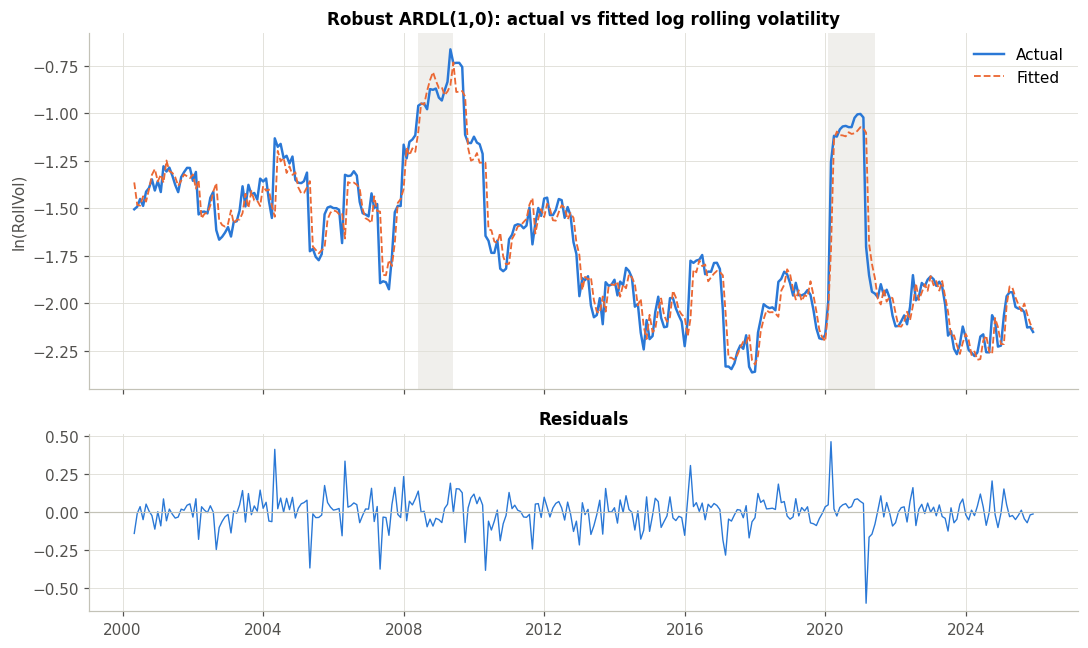

In [28]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
shade_dummies(ax[0]); ax[0].plot(des2.index, des2[Y2], color=C["blue"], label="Actual")
ax[0].plot(des2.index, res2.fittedvalues, color=C["orange"], lw=1.2, ls="--", label="Fitted")
ax[0].set_ylabel("ln(RollVol)"); ax[0].legend(loc="upper right")
ax[0].set_title(f"Robust ARDL({P2},{Q2}): actual vs fitted log rolling volatility")
ax[1].plot(des2.index, res2.resid, color=C["blue"], lw=0.9); ax[1].axhline(0, color=C["axis"], lw=0.8)
ax[1].set_title("Residuals"); year_axis(ax[1]); fig.tight_layout(); save_fig(fig, "F06_ardl_robust_fit")

**Sensitivity to the Int_Rate correction.** The robust ARDL is re-estimated with the uncorrected March-2007 value
(54.32) to show how much the data fix matters.

In [29]:
raw_int = pd.read_excel(DATA_FILE, sheet_name=DATA_SHEET).set_index("Date")["Int_Rate"]
df_s = df.copy(); df_s["Int_Rate"] = raw_int.reindex(df_s.index); EST_s = df_s.loc[df_s["RollVol"].notna()].copy()
des_s = ardl_frame(EST_s, Y2, REG2, P2, Q2, DUM2, df_s)
res_s = sm.OLS(des_s[Y2], sm.add_constant(des_s.drop(columns=Y2))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
sens = pd.DataFrame({"Coef (corrected)": res2.params, "p (corrected)": res2.pvalues,
                     "Coef (uncorrected 54.32)": res_s.params, "p (uncorrected)": res_s.pvalues})
save_table(sens.round(5), "T20b_ardl_robust_int_rate_sensitivity")

,Coef (corrected),p (corrected),Coef (uncorrected 54.32),p (uncorrected)
const,-0.16631,0.01339,-0.15196,0.01425
lnRollVol_L1,0.83237,0.00000,0.82836,0.00000
TPU,-0.00005,0.30622,-0.00006,0.23569
GPR,-0.00021,0.06165,-0.00023,0.03281
FX_USD,-0.00321,0.00019,-0.00331,0.00006
CPI_GR,-0.00254,0.35016,-0.00254,0.34141
Int_Rate,0.00269,0.44192,0.00035,0.77641
Output_Gap,-0.00071,0.48294,-0.00063,0.52958
MPU,0.00035,0.01161,0.00038,0.00536
US_VIX,0.00261,0.12160,0.00260,0.12402


,Coef (corrected),p (corrected),Coef (uncorrected 54.32),p (uncorrected)
const,-0.16631,0.01339,-0.15196,0.01425
lnRollVol_L1,0.83237,0.00000,0.82836,0.00000
TPU,-0.00005,0.30622,-0.00006,0.23569
GPR,-0.00021,0.06165,-0.00023,0.03281
FX_USD,-0.00321,0.00019,-0.00331,0.00006
CPI_GR,-0.00254,0.35016,-0.00254,0.34141
Int_Rate,0.00269,0.44192,0.00035,0.77641
Output_Gap,-0.00071,0.48294,-0.00063,0.52958
MPU,0.00035,0.01161,0.00038,0.00536
US_VIX,0.00261,0.12160,0.00260,0.12402


## 8. Structural VAR — {TPU, GPR, RollVol}, Cholesky ordering TPU → GPR → RollVol
Levels VAR (the Johansen test on this system does not support differencing), lag length by AIC (max 12),
orthogonalised IRFs over 24 months with Monte-Carlo 95 % bands (1,000 draws), FEVD, and the alternative
ordering GPR → TPU → RollVol as a robustness check. IRFs are in **percentage points of annualised volatility** per
one-standard-deviation structural shock.

In [30]:
SV = ["TPU", "GPR", "RollVol"]
var_mod = VAR(EST[SV]); sel = var_mod.select_order(maxlags=12)
lag_tab = pd.DataFrame({"AIC": [sel.aic], "BIC": [sel.bic], "HQIC": [sel.hqic], "FPE": [sel.fpe]}, index=["Selected lag"])
save_table(lag_tab, "T21_svar_lag_selection")
p_var = max(int(sel.aic), 1)
var_res = var_mod.fit(p_var); print(var_res.summary())
print("VAR stable (all roots outside unit circle):", var_res.is_stable())
P_chol = np.linalg.cholesky(var_res.sigma_u)
save_table(pd.DataFrame(P_chol, index=SV, columns=[f"shock {s}" for s in SV]).round(6), "T22_svar_impact_matrix")

H = 24
irf = var_res.irf(H)
lo, hi = irf.errband_mc(orth=True, repl=1000, signif=0.05, seed=SEED)
vi = SV.index("RollVol")
irf_tab = pd.DataFrame({f"{s}→RollVol": irf.orth_irfs[:, vi, SV.index(s)] * 100 for s in SV})
for s in SV:
    irf_tab[f"{s} lo95"] = lo[:, vi, SV.index(s)] * 100; irf_tab[f"{s} hi95"] = hi[:, vi, SV.index(s)] * 100
irf_tab.index.name = "Horizon (months)"; save_table(irf_tab.round(5), "T23_svar_irf_rollvol", show=False)

fe = var_res.fevd(H); fevd_tab = pd.DataFrame(fe.decomp[vi] * 100, columns=SV, index=range(1, H + 1))
fevd_tab.index.name = "Horizon (months ahead)"
save_table(fevd_tab.loc[[1, 3, 6, 12, 18, 24]].round(2), "T24_svar_fevd_rollvol")

alt = ["GPR", "TPU", "RollVol"]; var_alt = VAR(EST[alt]).fit(p_var); irf_alt = var_alt.irf(H)
rob = pd.DataFrame({
    "Base peak |IRF| (pp)": [np.abs(irf.orth_irfs[:, vi, SV.index(s)]).max() * 100 for s in ["TPU", "GPR"]],
    "Alt. peak |IRF| (pp)": [np.abs(irf_alt.orth_irfs[:, 2, alt.index(s)]).max() * 100 for s in ["TPU", "GPR"]],
    "Base FEVD 24m (%)": [fevd_tab.loc[24, s] for s in ["TPU", "GPR"]],
    "Alt. FEVD 24m (%)": [var_alt.fevd(H).decomp[2][-1, alt.index(s)] * 100 for s in ["TPU", "GPR"]]}, index=["TPU", "GPR"])
save_table(rob.round(4), "T25_svar_ordering_robustness")
KEY["svar"] = {"lag": p_var, "stable": bool(var_res.is_stable()),
               "fevd": {int(h): [round(fevd_tab.loc[h, s], 2) for s in SV] for h in [1, 6, 12, 24]},
               "irf_band_excludes_zero": {s: bool(((lo[1:, vi, SV.index(s)] > 0) | (hi[1:, vi, SV.index(s)] < 0)).any()) for s in ["TPU", "GPR"]}}

,AIC,BIC,HQIC,FPE
Selected lag,1,1,1,1


  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Sat, 14, Nov, 2026
Time:                     20:53:31
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                    7.79737
Nobs:                     308.000    HQIC:                   7.71015
Log likelihood:          -2477.51    FPE:                    2104.95
AIC:                      7.65204    Det(Omega_mle):         2025.02
--------------------------------------------------------------------
Results for equation TPU
                coefficient       std. error           t-stat            prob
-----------------------------------------------------------------------------
const             14.862392        10.820723            1.374           0.170
L1.TPU             0.887458         0.026910           32.979           0.000
L1.GPR             0.037595         0.057602            0.653           0.

,shock TPU,shock GPR,shock RollVol
TPU,51.248177,0.000000,0.00000
GPR,-1.764385,35.025663,0.00000
RollVol,0.000198,-0.000347,0.02507


,TPU,GPR,RollVol
Horizon (months ahead),,,
1,0.01,0.02,99.97
3,0.02,0.01,99.97
6,0.14,0.01,99.86
12,0.44,0.01,99.55
18,0.71,0.01,99.28
24,0.91,0.01,99.08


,Base peak |IRF| (pp),Alt. peak |IRF| (pp),Base FEVD 24m (%),Alt. FEVD 24m (%)
TPU,0.1870,0.1861,0.9098,0.8995
GPR,0.0347,0.0357,0.0107,0.0210


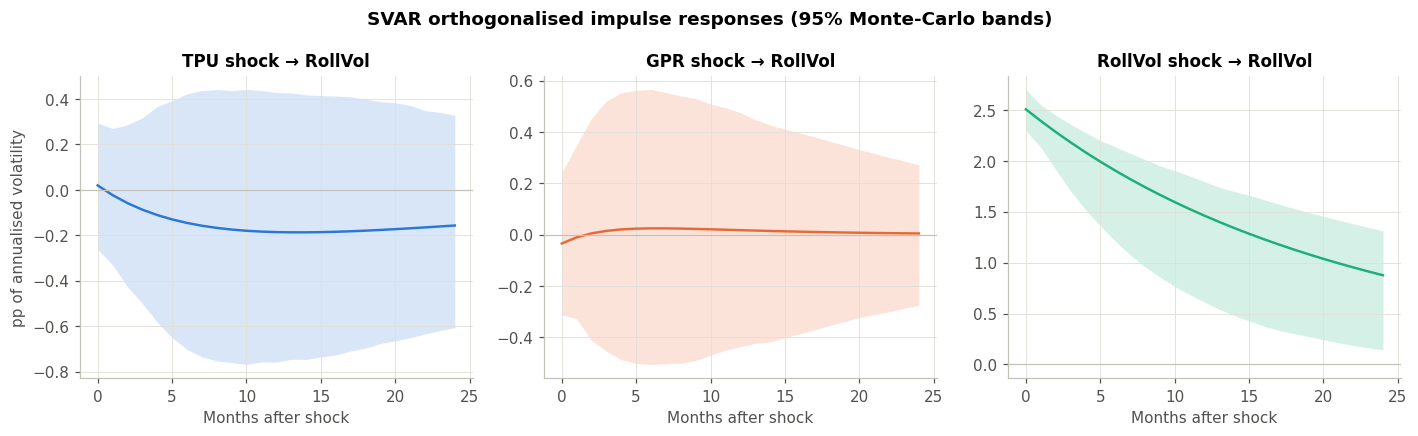

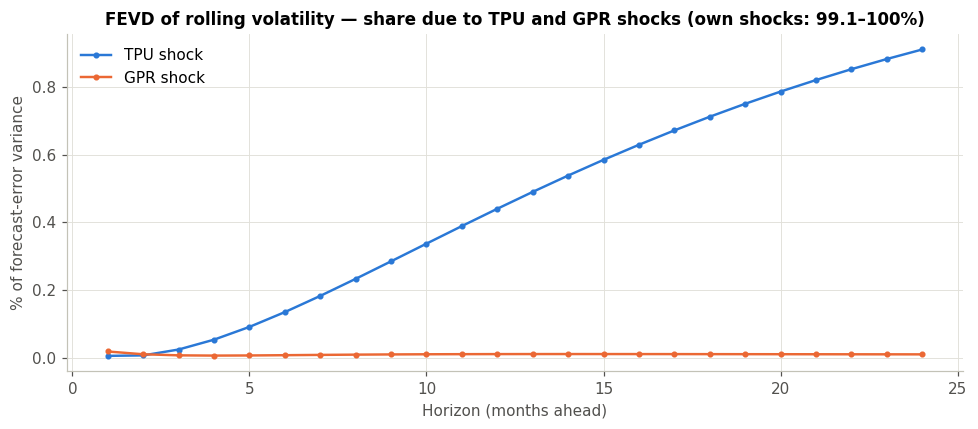

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharex=True)
for a, s, col in zip(axes, SV, [C["blue"], C["orange"], C["aqua"]]):
    a.fill_between(irf_tab.index, irf_tab[f"{s} lo95"], irf_tab[f"{s} hi95"], color=col, alpha=0.18, lw=0)
    a.plot(irf_tab.index, irf_tab[f"{s}→RollVol"], color=col); a.axhline(0, color=C["axis"], lw=0.8)
    a.set_title(f"{s} shock → RollVol"); a.set_xlabel("Months after shock")
axes[0].set_ylabel("pp of annualised volatility")
fig.suptitle("SVAR orthogonalised impulse responses (95% Monte-Carlo bands)", fontweight="bold"); fig.tight_layout()
save_fig(fig, "F07_svar_irf")

fig, ax = plt.subplots(figsize=(9, 4))
for s_, col in zip(["TPU", "GPR"], [C["blue"], C["orange"]]):
    ax.plot(fevd_tab.index, fevd_tab[s_], color=col, label=f"{s_} shock", marker="o", ms=3)
ax.set_xlabel("Horizon (months ahead)"); ax.set_ylabel("% of forecast-error variance"); ax.legend(loc="upper left")
ax.set_title(f"FEVD of rolling volatility — share due to TPU and GPR shocks (own shocks: {fevd_tab['RollVol'].min():.1f}–100%)")
fig.tight_layout(); save_fig(fig, "F08_svar_fevd")

## 9. Time-varying-parameter regression (Kalman filter)
*It is a single-equation regression with random-walk coefficients:*
$y_t=x_t'\beta_t+u_t,\;\beta_t=\beta_{t-1}+\eta_t$, with $y$=standardised RollVol, $x_t$=[1, TPU, GPR, TPU×GPR]
(standardised), $Q=0.005\,I$, $R=0.5$, diffuse start $P_0=10I$ — the original settings. Coefficients are the **filtered**
estimates. A month is "significant" when the 95 % band excludes zero (both signs are counted; the original counted
only positive). Sensitivity to $Q$ is reported through the log-likelihood.

In [32]:
from sklearn.preprocessing import StandardScaler
TV = ["TPU", "GPR", "TPU_GPR"]
sc_tv = StandardScaler().fit(EST[TV + ["RollVol"]])
Z = pd.DataFrame(sc_tv.transform(EST[TV + ["RollVol"]]), index=EST.index, columns=TV + ["RollVol"])
y_tv = Z["RollVol"].values; X_tv = np.column_stack([np.ones(len(Z)), Z[TV].values]); reg_names = ["Intercept"] + TV

def kalman_tvp(y, X, q=0.005, r=0.5):
    T, k = X.shape; Q = q * np.eye(k); b = np.zeros(k); P = 10 * np.eye(k)
    B = np.zeros((T, k)); PP = np.zeros((T, k, k)); fit = np.zeros(T); ll = 0.0
    for t in range(T):
        Pp = P + Q; x = X[t]; yhat = x @ b; v = y[t] - yhat; S = x @ Pp @ x + r; K = Pp @ x / S
        b = b + K * v; P = (np.eye(k) - np.outer(K, x)) @ Pp
        B[t] = b; PP[t] = P; fit[t] = yhat; ll += -0.5 * (np.log(2 * np.pi * S) + v**2 / S)
    return B, PP, fit, ll

B_tv, P_tv, fit_tv, ll_tv = kalman_tvp(y_tv, X_tv)
qgrid = [0.001, 0.0025, 0.005, 0.01, 0.02]
save_table(pd.DataFrame({"Q": qgrid, "Log-likelihood": [kalman_tvp(y_tv, X_tv, q=q)[3] for q in qgrid]}).round(3),
           "T26_tvp_Q_sensitivity", index=False)

def spells(mask, idx):
    out, start = [], None
    for i, m in enumerate(mask):
        if m and start is None: start = i
        if (not m or i == len(mask) - 1) and start is not None:
            end = i if m else i - 1; out.append(f"{idx[start]:%b-%Y}–{idx[end]:%b-%Y}"); start = None
    return "; ".join(out) if out else "—"

se_tv = np.sqrt(np.stack([P_tv[:, i, i] for i in range(4)], axis=1))
rows = []
for i, v in enumerate(reg_names[1:], start=1):
    pos = B_tv[:, i] > 1.96 * se_tv[:, i]; neg = B_tv[:, i] < -1.96 * se_tv[:, i]
    rows.append({"Variable": v, "Sig. positive months": int(pos.sum()), "Sig. negative months": int(neg.sum()),
                 "% of months significant": 100 * (pos.sum() + neg.sum()) / len(pos),
                 "Positive spells": spells(pos, Z.index), "Negative spells": spells(neg, Z.index)})
tvp_sig = pd.DataFrame(rows).set_index("Variable"); save_table(tvp_sig.round(1), "T27_tvp_significant_months")
KEY["tvp"] = {"N": len(Z), "loglik_Q0.005": round(ll_tv, 3),
              "sig": {v: [int(tvp_sig.loc[v, "Sig. positive months"]), int(tvp_sig.loc[v, "Sig. negative months"])] for v in TV},
              "spells_pos": {v: tvp_sig.loc[v, "Positive spells"] for v in TV}}
tvp_out = pd.DataFrame({f"beta_{n}": B_tv[:, i] for i, n in enumerate(reg_names)}, index=Z.index)
for i, n in enumerate(reg_names): tvp_out[f"se_{n}"] = se_tv[:, i]
tvp_out["actual_std"] = y_tv; tvp_out["fitted_std"] = fit_tv
save_table(tvp_out.round(5), "T28_tvp_coefficient_paths", show=False)

,Q,Log-likelihood
0,0.001,-350.211
1,0.002,-327.517
2,0.005,-312.625
3,0.010,-301.990
4,0.020,-298.280


,Sig. positive months,Sig. negative months,% of months significant,Positive spells,Negative spells
Variable,,,,,
TPU,0,0,0.0,—,—
GPR,0,19,6.1,—,Jul-2020–Jan-2022
TPU_GPR,0,0,0.0,—,—


,beta_Intercept,beta_TPU,beta_GPR,beta_TPU_GPR,se_Intercept,se_TPU,se_GPR,se_TPU_GPR,actual_std,fitted_std
Date,,,,,,,,,,
2000-04-01,0.22816,-0.07052,-0.26636,-0.09018,2.50003,3.10586,2.21081,3.06896,0.60795,0.00000
2000-05-01,-0.00707,-0.08988,-0.43888,-0.09453,1.36973,3.10188,1.59296,3.06953,0.24620,0.41609
2000-06-01,-0.01134,0.11717,-0.48977,0.00013,1.37130,2.81806,1.56227,3.01243,0.28197,0.43917
2000-07-01,0.01836,0.12087,-0.43097,0.00174,1.34520,2.81874,1.46559,3.01322,0.39294,0.48996
2000-08-01,0.09535,0.13649,-0.30836,-0.00539,1.30402,2.81879,1.36514,3.01389,0.29292,0.49534
...,...,...,...,...,...,...,...,...,...,...
2025-08-01,-0.85614,-0.21449,-0.31400,0.27415,0.32401,0.40591,0.41908,0.42976,-0.82018,-0.85596
2025-09-01,-0.85411,-0.20828,-0.31272,0.27172,0.32937,0.39479,0.42431,0.43308,-0.84739,-0.89398
2025-10-01,-0.85756,-0.20989,-0.31677,0.26338,0.33560,0.40084,0.42879,0.43308,-0.96625,-0.86014


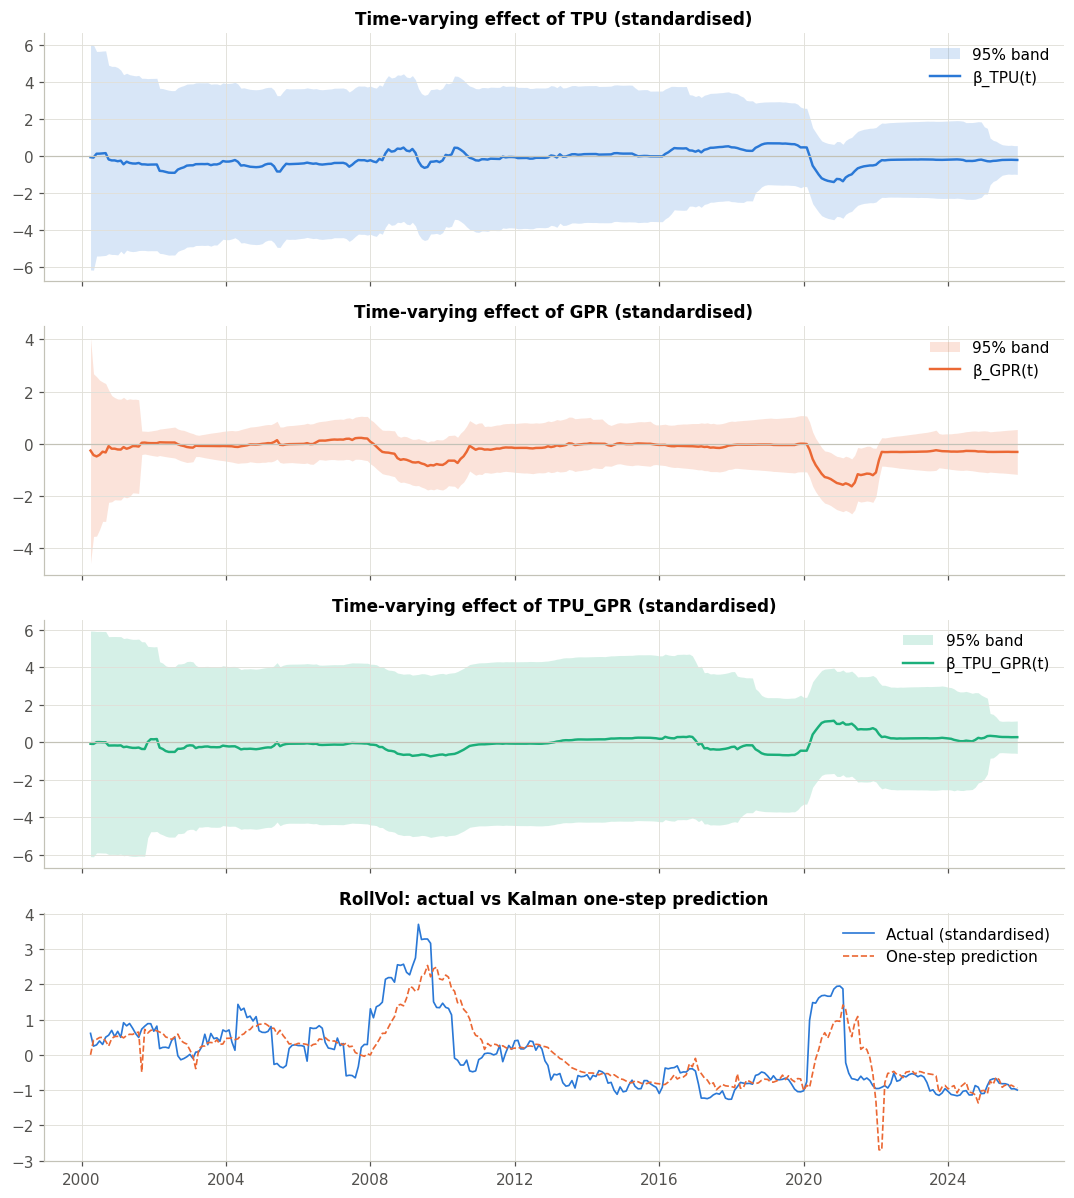

In [33]:
fig, axes = plt.subplots(4, 1, figsize=(10, 11), sharex=True)
for a, (i, v), col in zip(axes, list(enumerate(reg_names[1:], start=1)), [C["blue"], C["orange"], C["aqua"]]):
    b, s = B_tv[:, i], se_tv[:, i]
    a.fill_between(Z.index, b - 1.96 * s, b + 1.96 * s, color=col, alpha=0.18, lw=0, label="95% band")
    a.plot(Z.index, b, color=col, label=f"β_{v}(t)"); a.axhline(0, color=C["axis"], lw=0.8)
    a.set_title(f"Time-varying effect of {v} (standardised)"); a.legend(loc="upper right")
axes[3].plot(Z.index, y_tv, color=C["blue"], lw=1.1, label="Actual (standardised)")
axes[3].plot(Z.index, fit_tv, color=C["orange"], lw=1.1, ls="--", label="One-step prediction")
axes[3].set_title("RollVol: actual vs Kalman one-step prediction"); axes[3].legend(loc="upper right")
year_axis(axes[3]); fig.tight_layout(); save_fig(fig, "F09_tvp_coefficients")

## 10. Machine learning
**Target:** `RollVol` at month *t*. **Features (52):** the ten base variables (TPU, GPR, TPU×GPR, 7 controls) at *t*
and lags 1–3, `RollVol` lags 1–3, and 3-/6-month rolling means and 3-month rolling SDs of TPU, GPR and TPU×GPR —
the original feature set. Because contemporaneous regressors are included this is a *nowcasting* exercise
(explaining this month's volatility from information dated ≤ t), as in the original code.

**Split:** train = all months before Dec-2020, test = Dec-2020 → Dec-2025 (61 months; the original test window).
Scaling is fitted on the training set only. All hyper-parameter tuning uses `TimeSeriesSplit(5)` inside the training set.

**Scope:** benchmarks, penalised regressions, random forest and XGBoost. The LSTM and Temporal Fusion Transformers were thought of but had to be dropped because of lack of ample data.

**Changes from the original ML code (all fixes, see discrepancy log):** features are built on the full panel (no rows lost);
penalised regressions use time-series CV instead of plain K-fold; QLIKE uses the standard
variance-based definition; naive and AR(1) benchmarks are added; the RF walk-forward is evaluated on the same test window.

In [34]:
from sklearn.linear_model import LassoCV, RidgeCV, ElasticNetCV, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error
import xgboost as xgb, shap

TARGET = "RollVol"
ML_BASE = ["TPU", "GPR", "TPU_GPR"] + CONTROLS
F = pd.DataFrame(index=df.index); F[TARGET] = df[TARGET]
for v in ML_BASE: F[v] = df[v]
for v in ML_BASE:
    for l in (1, 2, 3): F[f"{v}_L{l}"] = df[v].shift(l)
for l in (1, 2, 3): F[f"{TARGET}_L{l}"] = df[TARGET].shift(l)
for v in ["TPU", "GPR", "TPU_GPR"]:
    F[f"{v}_roll3"] = df[v].rolling(3).mean(); F[f"{v}_roll6"] = df[v].rolling(6).mean(); F[f"{v}_std3"] = df[v].rolling(3).std()
F = F.dropna()
FEATS = [c for c in F.columns if c != TARGET]
tr_mask = F.index < TEST_START
X_tr, X_te, y_tr, y_te = F.loc[tr_mask, FEATS], F.loc[~tr_mask, FEATS], F.loc[tr_mask, TARGET], F.loc[~tr_mask, TARGET]
scaler = StandardScaler().fit(X_tr)
Xs_tr = pd.DataFrame(scaler.transform(X_tr), index=X_tr.index, columns=FEATS)
Xs_te = pd.DataFrame(scaler.transform(X_te), index=X_te.index, columns=FEATS)
tscv = TimeSeriesSplit(n_splits=5)
print(f"Features: {len(FEATS)} | Train {X_tr.index[0]:%b-%Y}–{X_tr.index[-1]:%b-%Y} ({len(X_tr)}) | "
      f"Test {X_te.index[0]:%b-%Y}–{X_te.index[-1]:%b-%Y} ({len(X_te)})")

PRED = {}
def metrics(y, yhat):
    y, yhat = np.asarray(y), np.asarray(yhat); yhat_c = np.clip(yhat, 1e-4, None)
    ratio = y**2 / yhat_c**2
    return {"RMSE": np.sqrt(mean_squared_error(y, yhat)), "MAE": mean_absolute_error(y, yhat),
            "R² (OOS)": 1 - np.sum((y - yhat)**2) / np.sum((y - y.mean())**2), "QLIKE": np.mean(ratio - np.log(ratio) - 1)}

Features: 52 | Train Jul-2000–Nov-2020 (245) | Test Dec-2020–Dec-2025 (61)


### 10.1 Benchmarks: naive (σ̂ₜ = σₜ₋₁) and AR(1)

In [35]:
PRED["Naive (σₜ₋₁)"] = X_te[f"{TARGET}_L1"].values
ar1 = LinearRegression().fit(X_tr[[f"{TARGET}_L1"]], y_tr); PRED["AR(1)"] = ar1.predict(X_te[[f"{TARGET}_L1"]])

### 10.2 Penalised regressions (LASSO, Ridge, Elastic Net)

,Model,alpha,l1_ratio,Non-zero coefs
0,LASSO,0.00206,1.0,5
1,Ridge,26.56088,0.0,52
2,Elastic Net,0.00212,0.9,6


,Coefficient (standardised features)
RollVol_L1,0.075451
US_VIX,0.006342
MPU,0.002145
TPU_GPR,-0.000144
Int_Rate_L3,-0.000070


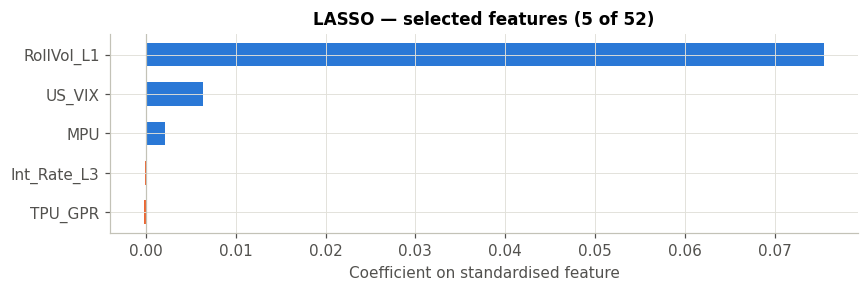

In [36]:
lasso = LassoCV(alphas=np.logspace(-4, 1, 100), cv=tscv, max_iter=100000).fit(Xs_tr, y_tr)
ridge = RidgeCV(alphas=np.logspace(-3, 3, 100), cv=tscv).fit(Xs_tr, y_tr)
enet = ElasticNetCV(l1_ratio=[.1, .3, .5, .7, .9], alphas=np.logspace(-4, 1, 50), cv=tscv, max_iter=100000).fit(Xs_tr, y_tr)
PRED["LASSO"], PRED["Ridge"], PRED["Elastic Net"] = lasso.predict(Xs_te), ridge.predict(Xs_te), enet.predict(Xs_te)
lasso_coef = pd.Series(lasso.coef_, index=FEATS); lasso_sel = lasso_coef[lasso_coef != 0].sort_values(key=np.abs, ascending=False)
pen = pd.DataFrame({"Model": ["LASSO", "Ridge", "Elastic Net"], "alpha": [lasso.alpha_, ridge.alpha_, enet.alpha_],
                    "l1_ratio": [1.0, 0.0, enet.l1_ratio_],
                    "Non-zero coefs": [int((lasso.coef_ != 0).sum()), len(FEATS), int((enet.coef_ != 0).sum())]})
save_table(pen.round(5), "T29_penalised_hyperparameters", index=False)
save_table(lasso_sel.rename("Coefficient (standardised features)").to_frame().round(6), "T30_lasso_selected_features")
KEY["lasso_selected"] = {k: round(v, 5) for k, v in lasso_sel.items()}

fig, ax = plt.subplots(figsize=(8, max(2.5, 0.35 * len(lasso_sel) + 1)))
ls_ = lasso_sel.sort_values()
ax.barh(ls_.index, ls_.values, color=np.where(ls_.values >= 0, C["blue"], C["orange"]), height=0.6)
ax.axvline(0, color=C["axis"], lw=0.8); ax.set_xlabel("Coefficient on standardised feature")
ax.set_title(f"LASSO — selected features ({len(lasso_sel)} of {len(FEATS)})"); fig.tight_layout(); save_fig(fig, "F10_lasso_coefficients")

### 10.3 Random forest (grid search with time-series CV) + expanding-window walk-forward on the test window

,Best params
0,"{'max_depth': 8, 'max_features': 0.5, 'min_sam..."


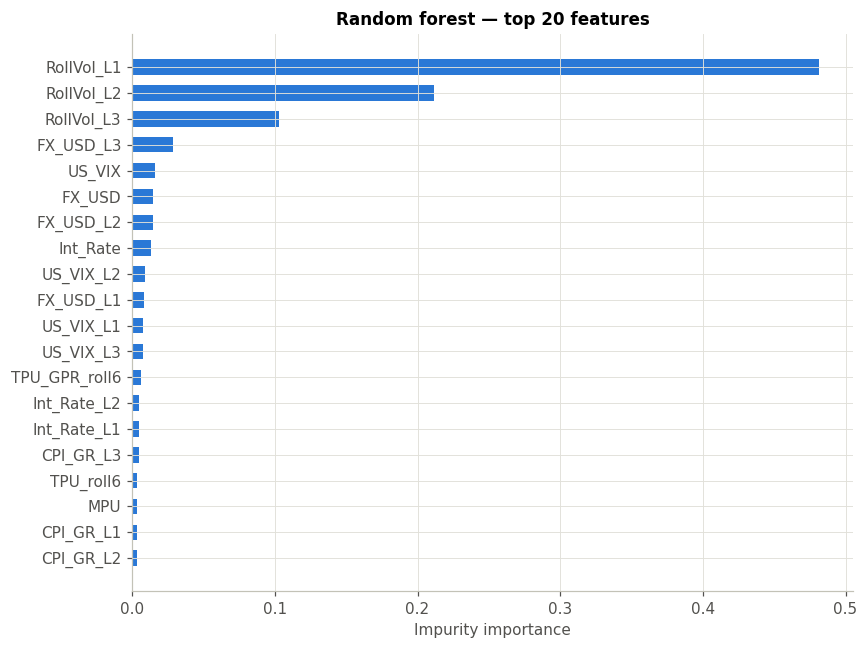

In [37]:
rf_grid = {"n_estimators": [200, 400], "max_depth": [4, 6, 8, None], "min_samples_leaf": [2, 5, 10], "max_features": ["sqrt", 0.5]}
rf_search = GridSearchCV(RandomForestRegressor(random_state=SEED, n_jobs=-1), rf_grid, cv=tscv,
                         scoring="neg_root_mean_squared_error", n_jobs=1).fit(X_tr, y_tr)
rf = rf_search.best_estimator_; PRED["Random Forest (static)"] = rf.predict(X_te)
wf = []
for d in X_te.index:
    m = RandomForestRegressor(**rf_search.best_params_, random_state=SEED, n_jobs=-1)
    m.fit(F.loc[F.index < d, FEATS], F.loc[F.index < d, TARGET]); wf.append(m.predict(F.loc[[d], FEATS])[0])
PRED["Random Forest (walk-forward)"] = np.array(wf)
imp_rf = pd.Series(rf.feature_importances_, index=FEATS).sort_values(ascending=False)
save_table(pd.DataFrame({"Best params": [str(rf_search.best_params_)]}), "T31_rf_best_params", index=False)
save_table(imp_rf.head(20).rename("Impurity importance").to_frame().round(5), "T32_rf_feature_importance", show=False)

fig, ax = plt.subplots(figsize=(8, 6)); t20 = imp_rf.head(20).sort_values()
ax.barh(t20.index, t20.values, color=C["blue"], height=0.6); ax.set_xlabel("Impurity importance")
ax.set_title("Random forest — top 20 features"); fig.tight_layout(); save_fig(fig, "F11_rf_importance")

### 10.4 XGBoost (randomised search, 60 draws) and SHAP attribution

In [38]:
xgb_space = {"n_estimators": [200, 400, 600], "max_depth": [3, 4, 5, 6], "learning_rate": [0.01, 0.05, 0.1],
             "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.6, 0.8, 1.0], "reg_alpha": [0, 0.1, 1.0],
             "reg_lambda": [1, 2, 5], "min_child_weight": [1, 3, 5]}
xgb_search = RandomizedSearchCV(xgb.XGBRegressor(objective="reg:squarederror", random_state=SEED, n_jobs=2, verbosity=0),
                                xgb_space, n_iter=60, cv=tscv, scoring="neg_root_mean_squared_error",
                                random_state=SEED, n_jobs=1).fit(Xs_tr, y_tr)
xgbm = xgb_search.best_estimator_; PRED["XGBoost"] = xgbm.predict(Xs_te)
save_table(pd.DataFrame({"Best params": [str(xgb_search.best_params_)]}), "T33_xgb_best_params", index=False)

explainer = shap.TreeExplainer(xgbm); shap_vals = explainer.shap_values(Xs_te)
shap_df = pd.DataFrame(shap_vals, index=Xs_te.index, columns=FEATS)
mean_abs = shap_df.abs().mean().sort_values(ascending=False)
shap_rank = pd.DataFrame({"Mean |SHAP|": mean_abs, "Rank": np.arange(1, len(mean_abs) + 1)})
save_table(shap_rank.head(20).round(6), "T34_shap_top20")
focus = ["TPU", "GPR", "TPU_GPR", "TPU_L1", "GPR_L1", "TPU_L2", "GPR_L2", "TPU_roll3", "GPR_roll3", "TPU_roll6", "GPR_roll6"]
save_table(shap_rank.loc[focus].sort_values("Rank").round(6), "T35_shap_tpu_gpr_features")
grp = {"TPU (all TPU features)": [f for f in FEATS if f.startswith("TPU") and not f.startswith("TPU_GPR")],
       "GPR (all GPR features)": [f for f in FEATS if f.startswith("GPR")],
       "TPU×GPR (all)": [f for f in FEATS if f.startswith("TPU_GPR")],
       "RollVol lags": [f for f in FEATS if f.startswith("RollVol")],
       "US_VIX (all)": [f for f in FEATS if f.startswith("US_VIX")]}
grp_tab = pd.Series({g: shap_df[c].sum(axis=1).abs().mean() for g, c in grp.items()}, name="Mean |Σ SHAP| of group")
save_table(grp_tab.sort_values(ascending=False).to_frame().round(6), "T36_shap_grouped")
KEY["shap_top5"] = {k: round(float(v), 5) for k, v in mean_abs.head(5).items()}
KEY["shap_focus"] = {k: [round(float(shap_rank.loc[k, "Mean |SHAP|"]), 6), int(shap_rank.loc[k, "Rank"])] for k in focus}

,Best params
0,"{'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha..."


,Mean |SHAP|,Rank
RollVol_L1,0.061653,1
FX_USD,0.011480,2
RollVol_L2,0.005769,3
MPU,0.005288,4
FX_USD_L3,0.003963,5
RollVol_L3,0.003176,6
CPI_GR_L3,0.002423,7
Int_Rate,0.002298,8
US_EPU,0.002113,9
MPU_L2,0.001963,10


,Mean |SHAP|,Rank
GPR,0.001693,12
TPU_roll3,0.001153,15
GPR_L1,0.001072,16
GPR_roll6,0.001020,18
GPR_L2,0.000670,23
GPR_roll3,0.000573,27
TPU_roll6,0.000470,31
TPU,0.000409,36
TPU_GPR,0.000330,38
TPU_L1,0.000326,39


,Mean |Σ SHAP| of group
RollVol lags,0.069307
US_VIX (all),0.003492
GPR (all GPR features),0.002924
TPU (all TPU features),0.001727
TPU×GPR (all),0.000824


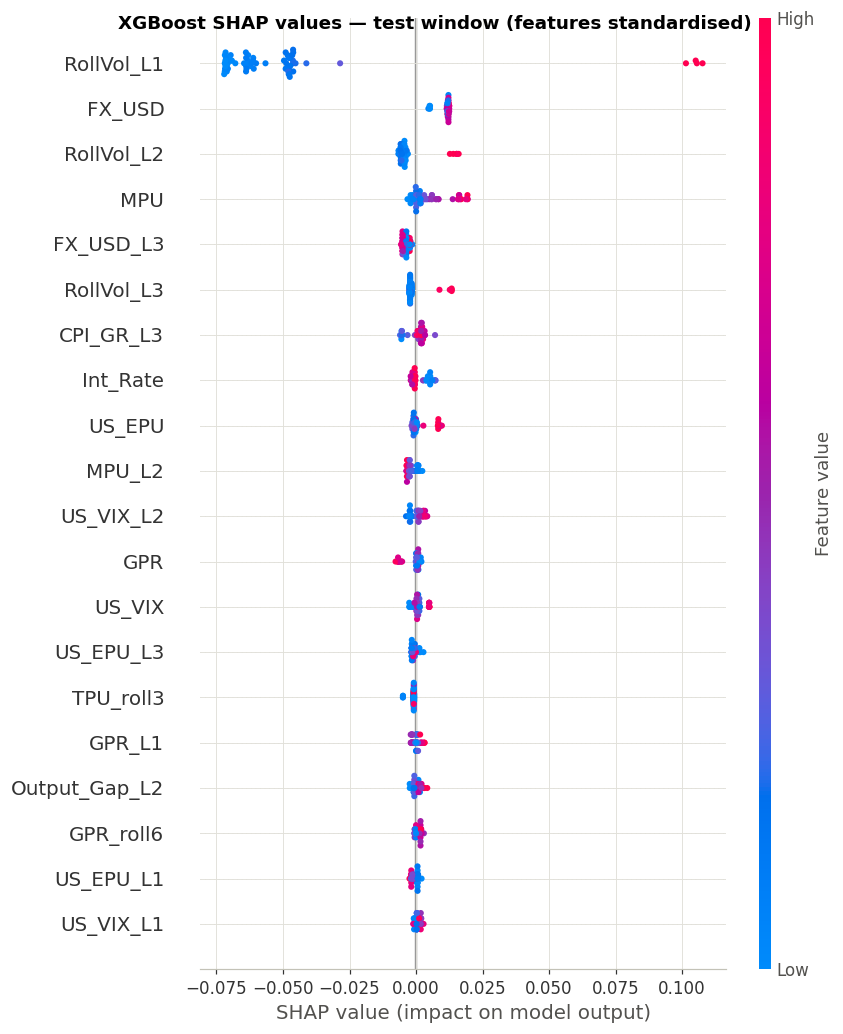

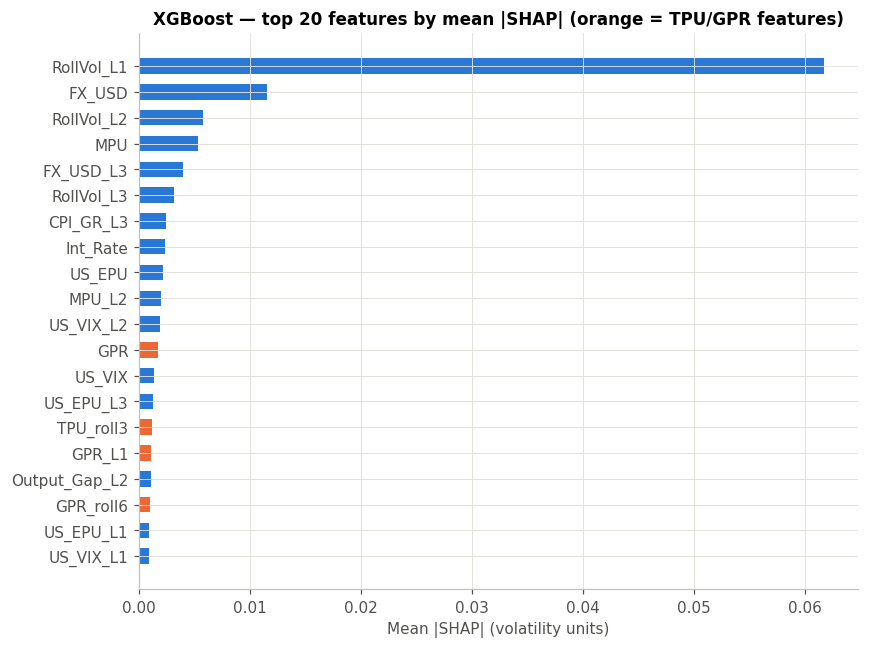

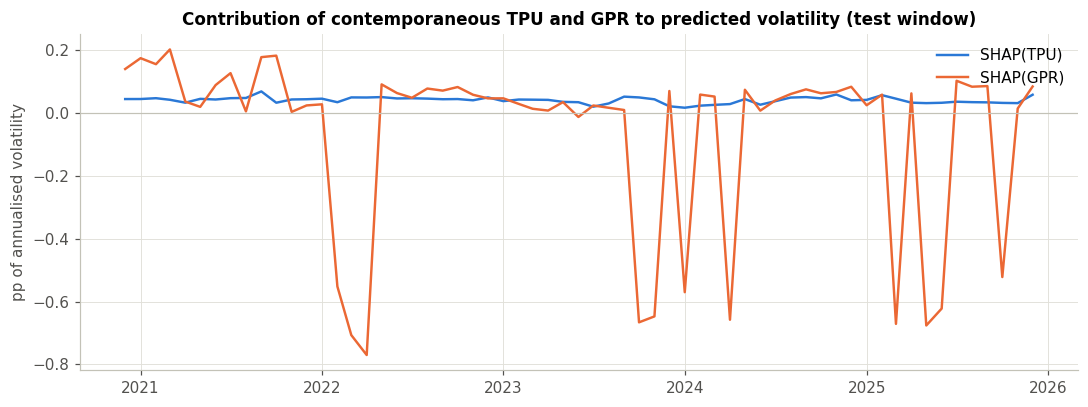

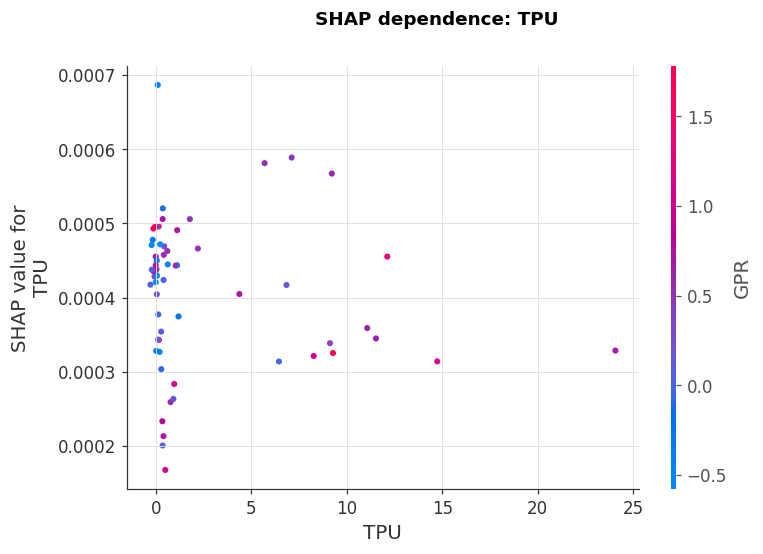

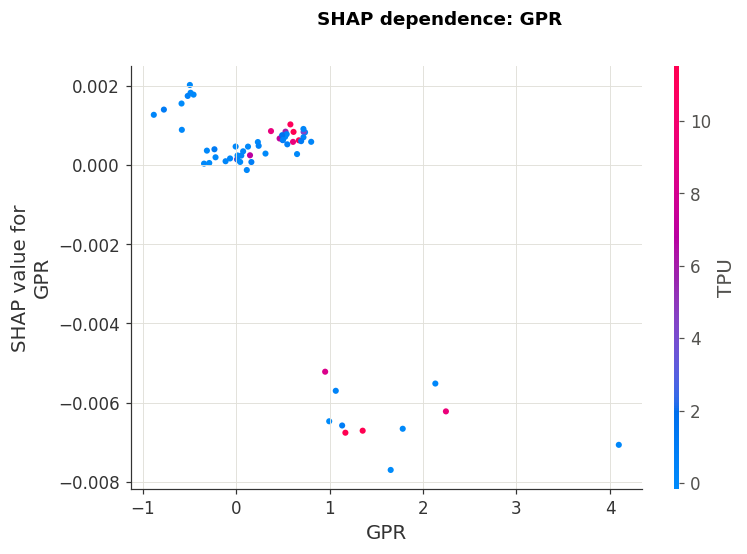

In [39]:
shap.summary_plot(shap_vals, Xs_te, feature_names=FEATS, max_display=20, show=False)
fig = plt.gcf(); fig.suptitle("XGBoost SHAP values — test window (features standardised)", fontweight="bold"); save_fig(fig, "F12_shap_beeswarm")

fig, ax = plt.subplots(figsize=(8, 6)); t = mean_abs.head(20).sort_values()
ax.barh(t.index, t.values, color=[C["orange"] if (i.startswith("TPU") or i.startswith("GPR")) else C["blue"] for i in t.index], height=0.6)
ax.set_xlabel("Mean |SHAP| (volatility units)"); ax.set_title("XGBoost — top 20 features by mean |SHAP| (orange = TPU/GPR features)")
fig.tight_layout(); save_fig(fig, "F13_shap_bar_top20")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(shap_df.index, shap_df["TPU"] * 100, color=C["blue"], label="SHAP(TPU)")
ax.plot(shap_df.index, shap_df["GPR"] * 100, color=C["orange"], label="SHAP(GPR)")
ax.axhline(0, color=C["axis"], lw=0.8); ax.set_ylabel("pp of annualised volatility"); ax.legend(loc="upper right")
ax.set_title("Contribution of contemporaneous TPU and GPR to predicted volatility (test window)")
fig.tight_layout(); save_fig(fig, "F14_shap_timeseries_tpu_gpr")

for v in ["TPU", "GPR"]:
    shap.dependence_plot(v, shap_vals, Xs_te, feature_names=FEATS, interaction_index="GPR" if v == "TPU" else "TPU", show=False)
    fig = plt.gcf(); fig.suptitle(f"SHAP dependence: {v}", fontweight="bold"); save_fig(fig, f"F15_shap_dependence_{v}")

### 10.5 Model comparison and Diebold–Mariano tests
DM test (squared-error loss, h = 1, Harvey–Leybourne–Newbold small-sample correction, t₆₀ reference) of each model
against the best model by RMSE. Negative DM ⇒ the challenger has *larger* losses.

In [40]:
res_ml = pd.DataFrame({m: metrics(y_te, p) for m, p in PRED.items()}).T
res_ml["RMSE / Naive"] = res_ml["RMSE"] / res_ml.loc["Naive (σₜ₋₁)", "RMSE"]
res_ml = res_ml.sort_values("RMSE"); best_m = res_ml.index[0]
def dm_test(e_best, e_ch):
    d = e_ch**2 - e_best**2; T_ = len(d); dm = d.mean() / np.sqrt(np.var(d, ddof=1) / T_)
    dm *= np.sqrt((T_ - 1) / T_); return -dm, 2 * (1 - stats.t.cdf(abs(dm), T_ - 1))
eb = y_te.values - PRED[best_m]
res_ml["DM vs best"] = [np.nan if m == best_m else dm_test(eb, y_te.values - PRED[m])[0] for m in res_ml.index]
res_ml["DM p-value"] = [np.nan if m == best_m else dm_test(eb, y_te.values - PRED[m])[1] for m in res_ml.index]
save_table(res_ml.round(5), "T37_ml_model_comparison")
KEY["ml"] = {m: {k: round(float(res_ml.loc[m, k]), 4) for k in ["RMSE", "MAE", "R² (OOS)", "QLIKE"]} for m in res_ml.index}
KEY["ml_best"] = best_m
pd.DataFrame({"Actual": y_te, **{m: p for m, p in PRED.items()}}, index=y_te.index).to_csv(TAB_DIR / "T38_ml_test_predictions.csv")

,RMSE,MAE,R² (OOS),QLIKE,RMSE / Naive,DM vs best,DM p-value
AR(1),0.02439,0.01099,0.79213,0.02127,0.99158,NaN,NaN
Naive (σₜ₋₁),0.02460,0.00983,0.78859,0.02036,1.00000,-0.32457,0.74663
Elastic Net,0.02572,0.01601,0.76889,0.03096,1.04554,-1.21551,0.22893
LASSO,0.02589,0.01631,0.76577,0.03183,1.05259,-1.33086,0.18827
Random Forest (walk-forward),0.02865,0.01493,0.71317,0.03338,1.16480,-1.94755,0.05615
Ridge,0.03167,0.01954,0.64954,0.08647,1.28752,-2.02983,0.04682
Random Forest (static),0.03959,0.03259,0.45247,0.09609,1.60931,-6.34563,0.00000
XGBoost,0.04205,0.03611,0.38231,0.11060,1.70932,-9.52020,0.00000


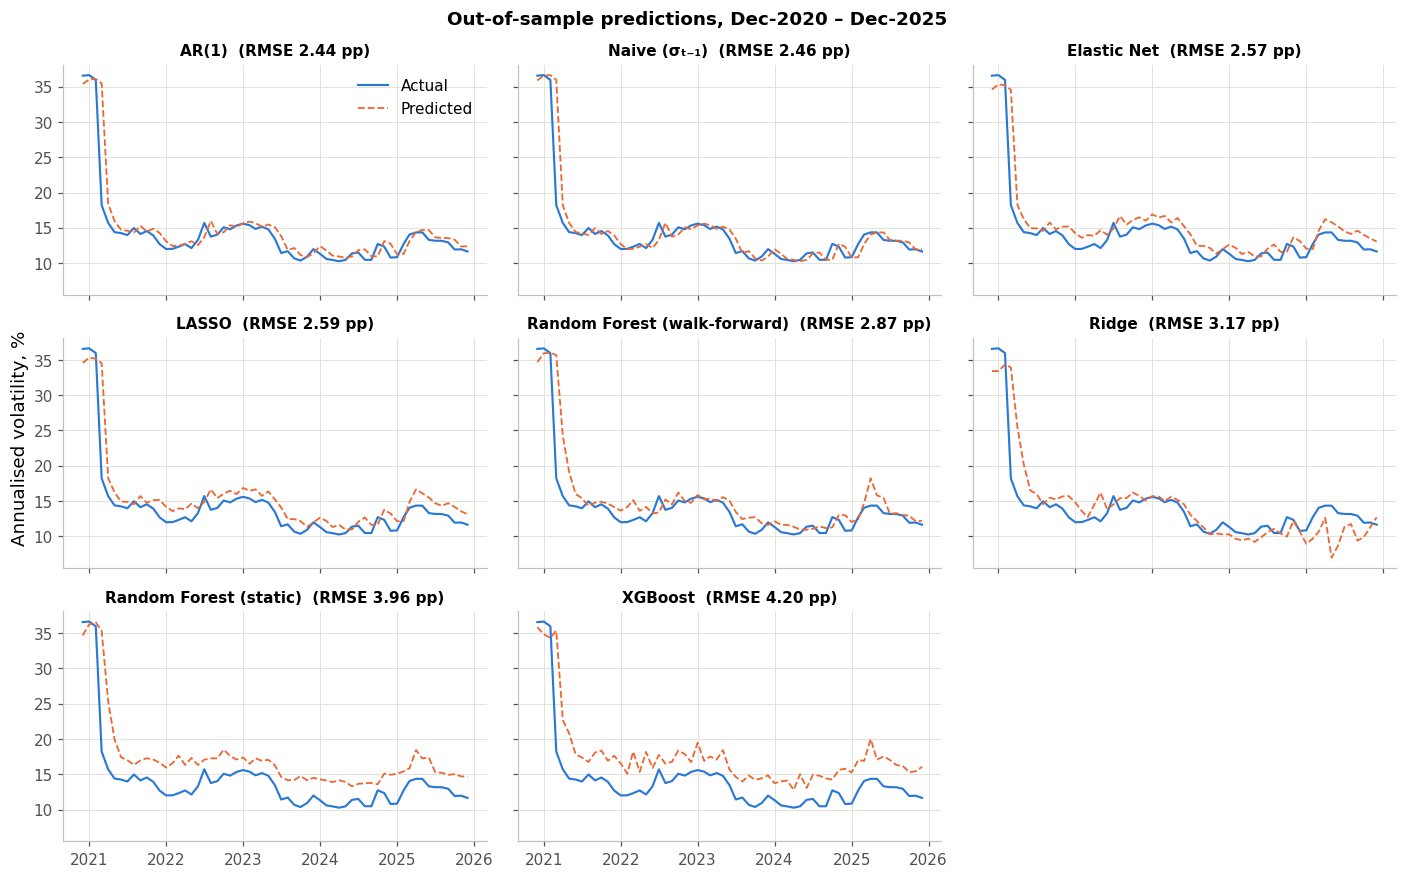

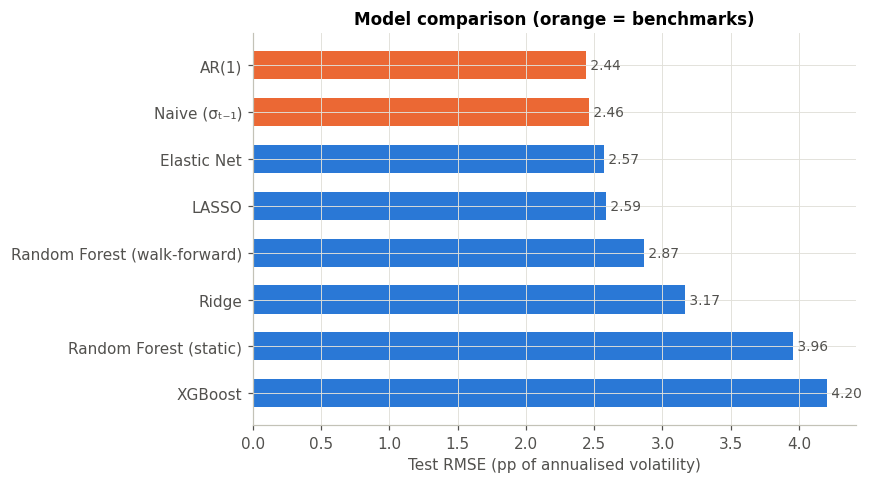

In [41]:
models = list(res_ml.index); n = len(models); ncol = 3; nrow = int(np.ceil(n / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 2.7 * nrow), sharex=True, sharey=True)
for a, m in zip(axes.flat, models):
    a.plot(y_te.index, y_te * 100, color=C["blue"], lw=1.4, label="Actual")
    a.plot(y_te.index, PRED[m] * 100, color=C["orange"], lw=1.2, ls="--", label="Predicted")
    a.set_title(f"{m}  (RMSE {res_ml.loc[m, 'RMSE']*100:.2f} pp)", fontsize=10); a.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for a in list(axes.flat)[n:]: a.axis("off")
axes.flat[0].legend(loc="upper right"); fig.supylabel("Annualised volatility, %")
fig.suptitle("Out-of-sample predictions, Dec-2020 – Dec-2025", fontweight="bold"); fig.tight_layout(); save_fig(fig, "F16_ml_predictions")

fig, ax = plt.subplots(figsize=(8, 4.5)); rr = res_ml["RMSE"].sort_values(ascending=False) * 100
ax.barh(rr.index, rr.values, color=[C["orange"] if "Naive" in i or "AR(1)" in i else C["blue"] for i in rr.index], height=0.6)
for y_, v in enumerate(rr.values): ax.text(v, y_, f" {v:.2f}", va="center", fontsize=9, color=C["ink2"])
ax.set_xlabel("Test RMSE (pp of annualised volatility)"); ax.set_title("Model comparison (orange = benchmarks)")
fig.tight_layout(); save_fig(fig, "F17_ml_rmse_comparison")

## 11. Key results summary

In [42]:
def _clean(o):
    if isinstance(o, dict): return {k: _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.floating,)): return round(float(o), 6)
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
KEY = _clean(KEY)
summary_rows = [
    ("Sample", KEY["sample"]),
    ("RollVol mean / SD / min / max (%)", KEY["rollvol_mean_sd_min_max"]),
    ("GARCH-X δ1 (TPU→variance) coef, p", KEY["garchx"]["δ1 TPU → variance"]),
    ("GARCH-X δ2 (GPR→variance) coef, p", KEY["garchx"]["δ2 GPR → variance"]),
    ("GARCH-X α+β", KEY["garchx_persistence"]), ("LR test GARCH-X vs GARCH(1,1), p", KEY["garchx_LR_p"]),
    ("Johansen rank: full / 3-var", f"{KEY['johansen']['full_rank']} / {KEY['johansen']['three_rank']}"),
    ("Base ARDL R², RollVol_L1", f"{KEY['ardl_base']['R2']}, {KEY['ardl_base']['Y_L1']}"),
    ("Base ARDL bounds F (5% I0/I1) → conclusion", f"{KEY['ardl_base']['bounds_F']} {KEY['ardl_base']['bounds_5pct']} → {KEY['ardl_base']['bounds_conclusion']}"),
    ("Robust ARDL order", KEY["ardl_robust"]["order"]),
    ("Robust ARDL bounds F (5% I0/I1) → conclusion", f"{KEY['ardl_robust']['bounds_F']} {KEY['ardl_robust']['bounds_5pct']} → {KEY['ardl_robust']['bounds_conclusion']}"),
    ("Robust ARDL GPR SR coef, p", KEY["ardl_robust"]["coef_p"]["GPR"]),
    ("Robust ARDL half-life (months)", KEY["ardl_robust"]["half_life"]),
    ("SVAR lag; FEVD at 24m (TPU, GPR, own %)", f"{KEY['svar']['lag']}; {KEY['svar']['fevd'][24]}"),
    ("TVP significant months (pos, neg): TPU / GPR / TPU×GPR", f"{KEY['tvp']['sig']['TPU']} / {KEY['tvp']['sig']['GPR']} / {KEY['tvp']['sig']['TPU_GPR']}"),
    ("Best ML model (test RMSE)", f"{KEY['ml_best']} ({KEY['ml'][KEY['ml_best']]['RMSE']})"),
    ("Naive benchmark RMSE / R²", f"{KEY['ml']['Naive (σₜ₋₁)']['RMSE']} / {KEY['ml']['Naive (σₜ₋₁)']['R² (OOS)']}"),
    ("LASSO selected features", list(KEY["lasso_selected"].keys()))]
save_table(pd.DataFrame(summary_rows, columns=["Item", "Result"]).astype(str), "T00_key_results_summary", index=False)

with open(TAB_DIR / "key_results.json", "w") as f: json.dump(KEY, f, indent=2, default=str)
with pd.ExcelWriter(OUT_DIR / "results_tables.xlsx") as w:
    for name, (tab, ix) in sorted(TABLES.items()):
        tab.to_excel(w, sheet_name=name[:31], index=ix)
print(f"Saved {len(TABLES)} tables to outputs/results_tables.xlsx and {len(list(FIG_DIR.glob('*.png')))} figures.")

,Item,Result
0,Sample,Apr-2000 – Dec-2025 (N=309)
1,RollVol mean / SD / min / max (%),"[20.11, 8.49, 9.41, 51.45]"
2,"GARCH-X δ1 (TPU→variance) coef, p","[-0.0053, 0.095]"
3,"GARCH-X δ2 (GPR→variance) coef, p","[-0.0115, 0.418]"
4,GARCH-X α+β,0.937
5,"LR test GARCH-X vs GARCH(1,1), p",0.475
6,Johansen rank: full / 3-var,8 / 3
7,"Base ARDL R², RollVol_L1","0.9321, [0.8692, 0.0]"
8,Base ARDL bounds F (5% I0/I1) → conclusion,"3.626 [2.06, 3.24] → Reject H0 → long-run leve..."
9,Robust ARDL order,"[1, 0]"


Saved 40 tables to outputs/results_tables.xlsx and 18 figures.


## 12. Appendix — construction of the compiled variables (reference only)
The raw source files (IPI series with three base years, daily VIX / FX / call-money files, BBD and Caldara–Iacoviello
index downloads) are not part of this repository, so this cell is **not executed** (`RUN_PREPROCESSING = False`).
It documents the two non-trivial transformations used to build `Compiled.xlsx`; the many plotting / date-formatting
snippets of `UGP.ipynb` and `UGP_1.ipynb`, the daily-data volatility / realised-volatility / daily-GARCH code and the
`GARCH` and `RR_VOL` sheets are not needed for any result and are dropped.

1. **IPI splicing** (1993-94 → 2004-05 → 2011-12 base): ratio-splice the older series onto the newer one at the overlap month.
2. **Output gap**: HP filter on ln(IPI) with λ = 14,400; gap = 100 × cycle. *Note:* the `UGP_1` cell applied the filter to
   `IPI_11.xlsx` only; the gap in `Compiled.xlsx` spans 1996–2025, so it must have been computed on the spliced series —
   this cannot be verified without the raw files.
3. Daily series (US VIX, INR/USD, call-money rate) are averaged to calendar months; MPU / US-EPU / TPU / GPR are
   already monthly and are only re-dated to the first of the month.

In [43]:
# RUN_PREPROCESSING = False
# if RUN_PREPROCESSING:
#     from statsmodels.tsa.filters.hp_filter import hpfilter
#     def load_ipi(path):
#         s = pd.read_excel(path).iloc[:, :2]; s.columns = ["Date", "IPI"]
#         s["Date"] = pd.to_datetime(s["Date"], format="%d-%m-%Y", errors="coerce"); return s.dropna().set_index("Date")["IPI"].sort_index()
#     s1, s2_, s3 = load_ipi("IPI_94.xlsx"), load_ipi("IP_5.xlsx"), load_ipi("IPI_11.xlsx")
#     s2_adj = s2_ * (s3.loc["2013-01-01"] / s2_.loc["2013-01-01"])
#     ov = s1.index.intersection(s2_adj.index).max(); s1_adj = s1 * (s2_adj.loc[ov] / s1.loc[ov])
#     ipi = pd.concat([s1_adj[s1_adj.index < s2_adj.index.min()], s2_adj[s2_adj.index < s3.index.min()], s3]).sort_index()
#     cycle, trend = hpfilter(np.log(ipi), lamb=14400); output_gap = 100 * cycle
#     def monthly_mean(path, date_col="Date"):
#         d = pd.read_excel(path); d[date_col] = pd.to_datetime(d[date_col], dayfirst=True, errors="coerce")
#         return d.set_index(date_col).select_dtypes("number").resample("MS").mean()